In [2]:
import requests # used to make http requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler,LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import style
sns.set(rc={ #rc runtime configuration
    'figure.figsize':(20,20),
    'font.size':14,
})
inner_merged_df=pd.read_csv('vehicles.csv',index_col=0)


In [3]:
inner_merged_df.info

<bound method DataFrame.info of                       vin manufacturer  year            color    body_type  \
0       KNEQQMPI59JQMQFUS   Volkswagen  2023   metallic_black        Truck   
1       Y06254A9NYNT183XI         Audi  2021      matte_black  Convertible   
2       U8J8TBA70SBBGVXT1       Nissan  2020  metallic_silver        Wagon   
3       ZWEG0R44V9S72T8CO    Chevrolet  2012             gray          Van   
4       XRNFVKZUXQ4WJHJTK       Nissan  2009           purple    Hatchback   
...                   ...          ...   ...              ...          ...   
499741  CQKFTDB3PATH31NRK         Ford  2018           silver    Hatchback   
499742  XV0S95MH6Q96UT9V1          BMW  2018            green        Truck   
499743  FU6BSORX4Z369WJTM       Nissan  2005   metallic_brown        Coupe   
499744  OQBLQCK353L8VXN5I        Honda  2020  metallic_silver        Truck   
499745  K1YXRQOWFRG2M351R          BMW  2012    metallic_gray        Coupe   

       engine_type transmission

In [4]:
inner_merged_df.head()

,vin,manufacturer,year,color,body_type,engine_type,transmission,fuel_type,seating_capacity,kilometers_driven,vehicle_condition_status,selling_price,owner_name,owner_profession,owner_age,owner_district,proposed_purchase_price,purchase_date
0,KNEQQMPI59JQMQFUS,Volkswagen,2023,metallic_black,Truck,electric,manual,gasoline,6,19.84,inactive,5980.16,KARABO Nadege,librarian,49,east_nyagatare,6705.76,2024-01-24
1,Y06254A9NYNT183XI,Audi,2021,matte_black,Convertible,diesel,automatic,hybrid,10,19.83,active,8778.19,UWASE TETA Paola,economist,84,south_kamonyi,10008.46,2016-07-21
2,U8J8TBA70SBBGVXT1,Nissan,2020,metallic_silver,Wagon,petrol,manual,biodiesel,3,78.73,inactive,8921.27,IMANISINGIZWE KAMANA Adeodatus Clare,mechanic,38,kigali_gasabo,10219.33,2022-06-07
3,ZWEG0R44V9S72T8CO,Chevrolet,2012,gray,Van,petrol,automatic,ethanol,6,46.02,inactive,16953.98,IMANISHIMWE Emmanuel,hairdresser,33,west_rusizi,19288.22,2006-03-15
4,XRNFVKZUXQ4WJHJTK,Nissan,2009,purple,Hatchback,petrol,manual,gasoline,10,247.39,active,21727.87,IRASUBIZA Divine,baker,86,east_rwamagana,22848.39,2021-06-14


In [5]:
inner_merged_df.head(50).T #sub dataframe transposing

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
vin,KNEQQMPI59JQMQFUS,Y06254A9NYNT183XI,U8J8TBA70SBBGVXT1,ZWEG0R44V9S72T8CO,XRNFVKZUXQ4WJHJTK,1LO3MRZOB4X3Y1KST,HNHT7ZUBJ23KZDIV1,MPA62DRXSR7A89VZU,VHCAURU4ARUAYJ92M,29UVADC6HM51QNKB5,...,L2EH6TQ23PDGOIAK8,OHRXHPWHECHHJQQZS,M9TXM8DFQ68JDCLTB,NUY79PUP0JYAY1BQN,4T2JL4OUOAE1UF3AT,T6EFO6VUWKCN04XLW,GP8SBKXMHVRJJGD20,YP7RGQTMZZAO84F40,R0SFCTAVY3F3OFJFI,XUOIZ01NSZR4WYJVA
manufacturer,Volkswagen,Audi,Nissan,Chevrolet,Nissan,Ford,Nissan,Mercedes,Audi,Mercedes,...,Volkswagen,Honda,Volkswagen,Honda,Volkswagen,Ford,Honda,Chevrolet,Hyundai,Honda
year,2023,2021,2020,2012,2009,2008,2019,2017,2010,2018,...,2016,2019,2022,2005,2020,2014,2008,2023,2018,2000
color,metallic_black,matte_black,metallic_silver,gray,purple,metallic_red,silver,custom,matte_black,metallic_green,...,gray,black,red,white,yellow,metallic_red,custom,metallic_silver,metallic_blue,metallic_green
body_type,Truck,Convertible,Wagon,Van,Hatchback,SUV,Coupe,Sedan,SUV,Hatchback,...,Convertible,Coupe,Sedan,Convertible,Sedan,Van,Hatchback,Wagon,Sedan,Van
engine_type,electric,diesel,petrol,petrol,petrol,petrol,electric,diesel,electric,electric,...,diesel,electric,diesel,diesel,diesel,diesel,petrol,petrol,petrol,electric
transmission,manual,automatic,manual,automatic,manual,automatic,automatic,automatic,automatic,manual,...,automatic,manual,automatic,manual,manual,manual,automatic,manual,manual,manual
fuel_type,gasoline,hybrid,biodiesel,ethanol,gasoline,biodiesel,diesel,hybrid,gasoline,ethanol,...,gasoline,diesel,gasoline,hydrogen,ethanol,biodiesel,hydrogen,gasoline,biodiesel,ethanol
seating_capacity,6,10,3,6,10,8,6,4,3,7,...,7,9,3,4,10,8,2,7,6,8
kilometers_driven,19.84,19.83,78.73,46.02,247.39,14.62,13.88,43.33,101.99,117.6,...,150.11,8.82,2.73,165.74,44.75,90.6,302.36,17.02,84.5,440.03


In [6]:
inner_merged_df.tail()

,vin,manufacturer,year,color,body_type,engine_type,transmission,fuel_type,seating_capacity,kilometers_driven,vehicle_condition_status,selling_price,owner_name,owner_profession,owner_age,owner_district,proposed_purchase_price,purchase_date
499741,CQKFTDB3PATH31NRK,Ford,2018,silver,Hatchback,diesel,manual,hydrogen,10,73.91,inactive,10926.09,NDAYAMBAJE Patrick,dietitian,35,kigali_gasabo,12327.05,2011-05-18
499742,XV0S95MH6Q96UT9V1,BMW,2018,green,Truck,electric,automatic,ethanol,5,71.52,active,12021.33,ISHIMWE ARLENE,painter,78,west_ngororero,13389.50,2011-09-11
499743,FU6BSORX4Z369WJTM,Nissan,2005,metallic_brown,Coupe,petrol,automatic,ethanol,8,314.64,inactive,26053.90,ISHIMWE PRINCE ARNAUD,painter,93,south_nyamagabe,27714.55,2007-02-08
499744,OQBLQCK353L8VXN5I,Honda,2020,metallic_silver,Truck,diesel,manual,electric,4,62.66,active,8937.34,GISINGIZO Gloria,gardener,31,east_kayonza,10111.10,2021-07-09
499745,K1YXRQOWFRG2M351R,BMW,2012,metallic_gray,Coupe,electric,automatic,diesel,3,25.89,inactive,18671.52,INEZA TETA LANDRA,writer,88,south_huye,21025.82,2021-12-19


In [7]:
inner_merged_df.describe() #summary statistics for numerical columns

,year,seating_capacity,kilometers_driven,selling_price,owner_age,proposed_purchase_price
count,499746.000000,499746.000000,499746.000000,499746.000000,499746.000000,499746.000000
mean,2011.995770,5.999532,120.362064,17658.561496,59.013005,19425.720447
std,7.204957,2.583512,108.449333,7580.377670,23.933346,8358.384150
min,2000.000000,2.000000,0.000000,4500.000000,18.000000,4725.020000
25%,2006.000000,4.000000,30.730000,10965.082500,38.000000,12256.542500
50%,2012.000000,6.000000,89.290000,17522.420000,59.000000,19302.405000
75%,2018.000000,8.000000,185.150000,23976.257500,80.000000,26363.872500
max,2024.000000,10.000000,479.980000,31899.990000,100.000000,53801.410000


In [8]:
inner_merged_df.manufacturer.nunique()

10

In [9]:
inner_merged_df.manufacturer.nunique()

10

In [10]:
inner_merged_df.shape

(499746, 18)

In [11]:
sdf = inner_merged_df[['manufacturer','color','body_type','engine_type','year']]
sdf.describe()

,year
count,499746.000000
mean,2011.995770
std,7.204957
min,2000.000000
25%,2006.000000
50%,2012.000000
75%,2018.000000
max,2024.000000


In [12]:
sdf = inner_merged_df[['manufacturer','color','body_type','engine_type']]
sdf.describe()

,manufacturer,color,body_type,engine_type
count,499746,499746,499746,499746
unique,10,23,8,3
top,Audi,matte_black,Hatchback,petrol
freq,50272,21959,62759,166941


In [13]:
mdf=inner_merged_df[inner_merged_df['selling_price']>2000]
mdf

,vin,manufacturer,year,color,body_type,engine_type,transmission,fuel_type,seating_capacity,kilometers_driven,vehicle_condition_status,selling_price,owner_name,owner_profession,owner_age,owner_district,proposed_purchase_price,purchase_date
0,KNEQQMPI59JQMQFUS,Volkswagen,2023,metallic_black,Truck,electric,manual,gasoline,6,19.84,inactive,5980.16,KARABO Nadege,librarian,49,east_nyagatare,6705.76,2024-01-24
1,Y06254A9NYNT183XI,Audi,2021,matte_black,Convertible,diesel,automatic,hybrid,10,19.83,active,8778.19,UWASE TETA Paola,economist,84,south_kamonyi,10008.46,2016-07-21
2,U8J8TBA70SBBGVXT1,Nissan,2020,metallic_silver,Wagon,petrol,manual,biodiesel,3,78.73,inactive,8921.27,IMANISINGIZWE KAMANA Adeodatus Clare,mechanic,38,kigali_gasabo,10219.33,2022-06-07
3,ZWEG0R44V9S72T8CO,Chevrolet,2012,gray,Van,petrol,automatic,ethanol,6,46.02,inactive,16953.98,IMANISHIMWE Emmanuel,hairdresser,33,west_rusizi,19288.22,2006-03-15
4,XRNFVKZUXQ4WJHJTK,Nissan,2009,purple,Hatchback,petrol,manual,gasoline,10,247.39,active,21727.87,IRASUBIZA Divine,baker,86,east_rwamagana,22848.39,2021-06-14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499741,CQKFTDB3PATH31NRK,Ford,2018,silver,Hatchback,diesel,manual,hydrogen,10,73.91,inactive,10926.09,NDAYAMBAJE Patrick,dietitian,35,kigali_gasabo,12327.05,2011-05-18
499742,XV0S95MH6Q96UT9V1,BMW,2018,green,Truck,electric,automatic,ethanol,5,71.52,active,12021.33,ISHIMWE ARLENE,painter,78,west_ngororero,13389.50,2011-09-11
499743,FU6BSORX4Z369WJTM,Nissan,2005,metallic_brown,Coupe,petrol,automatic,ethanol,8,314.64,inactive,26053.90,ISHIMWE PRINCE ARNAUD,painter,93,south_nyamagabe,27714.55,2007-02-08
499744,OQBLQCK353L8VXN5I,Honda,2020,metallic_silver,Truck,diesel,manual,electric,4,62.66,active,8937.34,GISINGIZO Gloria,gardener,31,east_kayonza,10111.10,2021-07-09


In [14]:
nds=inner_merged_df.manufacturer
nds

0         Volkswagen
1               Audi
2             Nissan
3          Chevrolet
4             Nissan
             ...    
499741          Ford
499742           BMW
499743        Nissan
499744         Honda
499745           BMW
Name: manufacturer, Length: 499746, dtype: object

In [15]:
nds=inner_merged_df['manufacturer']
nds.count()

499746

In [16]:
nds.value_counts()

manufacturer
Audi          50272
Honda         50244
Chevrolet     50138
Ford          50138
Mercedes      49925
Nissan        49880
Hyundai       49876
BMW           49817
Toyota        49755
Volkswagen    49701
Name: count, dtype: int64

In [17]:
nds.nunique()

10

In [18]:
sdf.columns.to_list()

['manufacturer', 'color', 'body_type', 'engine_type']

In [19]:
sdf.columns

Index(['manufacturer', 'color', 'body_type', 'engine_type'], dtype='object')

In [20]:
inner_merged_df.isnull().sum()

vin                         0
manufacturer                0
year                        0
color                       0
body_type                   0
engine_type                 0
transmission                0
fuel_type                   0
seating_capacity            0
kilometers_driven           0
vehicle_condition_status    0
selling_price               0
owner_name                  0
owner_profession            0
owner_age                   0
owner_district              0
proposed_purchase_price     0
purchase_date               0
dtype: int64

In [21]:
inner_merged_df.isnull()

,vin,manufacturer,year,color,body_type,engine_type,transmission,fuel_type,seating_capacity,kilometers_driven,vehicle_condition_status,selling_price,owner_name,owner_profession,owner_age,owner_district,proposed_purchase_price,purchase_date
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499741,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
499742,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
499743,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
499744,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [22]:
inner_merged_df.isna().sum()

vin                         0
manufacturer                0
year                        0
color                       0
body_type                   0
engine_type                 0
transmission                0
fuel_type                   0
seating_capacity            0
kilometers_driven           0
vehicle_condition_status    0
selling_price               0
owner_name                  0
owner_profession            0
owner_age                   0
owner_district              0
proposed_purchase_price     0
purchase_date               0
dtype: int64

In [23]:
inner_merged_df['purchase_date'][:10].describe()

count             10
unique            10
top       2024-01-24
freq               1
Name: purchase_date, dtype: object

In [24]:
inner_merged_df['purchase_date'][:10].describe()

count             10
unique            10
top       2024-01-24
freq               1
Name: purchase_date, dtype: object

In [25]:
inner_merged_df.drop(["owner_name","vin"], axis=1, inplace=True)


In [26]:
"""
"""
inner_merged_df['selling_price'] = inner_merged_df['selling_price'].astype(float)
inner_merged_df['proposed_purchase_price'] = pd.to_numeric(inner_merged_df['proposed_purchase_price'],errors='coerce')
inner_merged_df['purchase_date'] = pd.to_datetime(inner_merged_df['purchase_date'], errors='coerce')

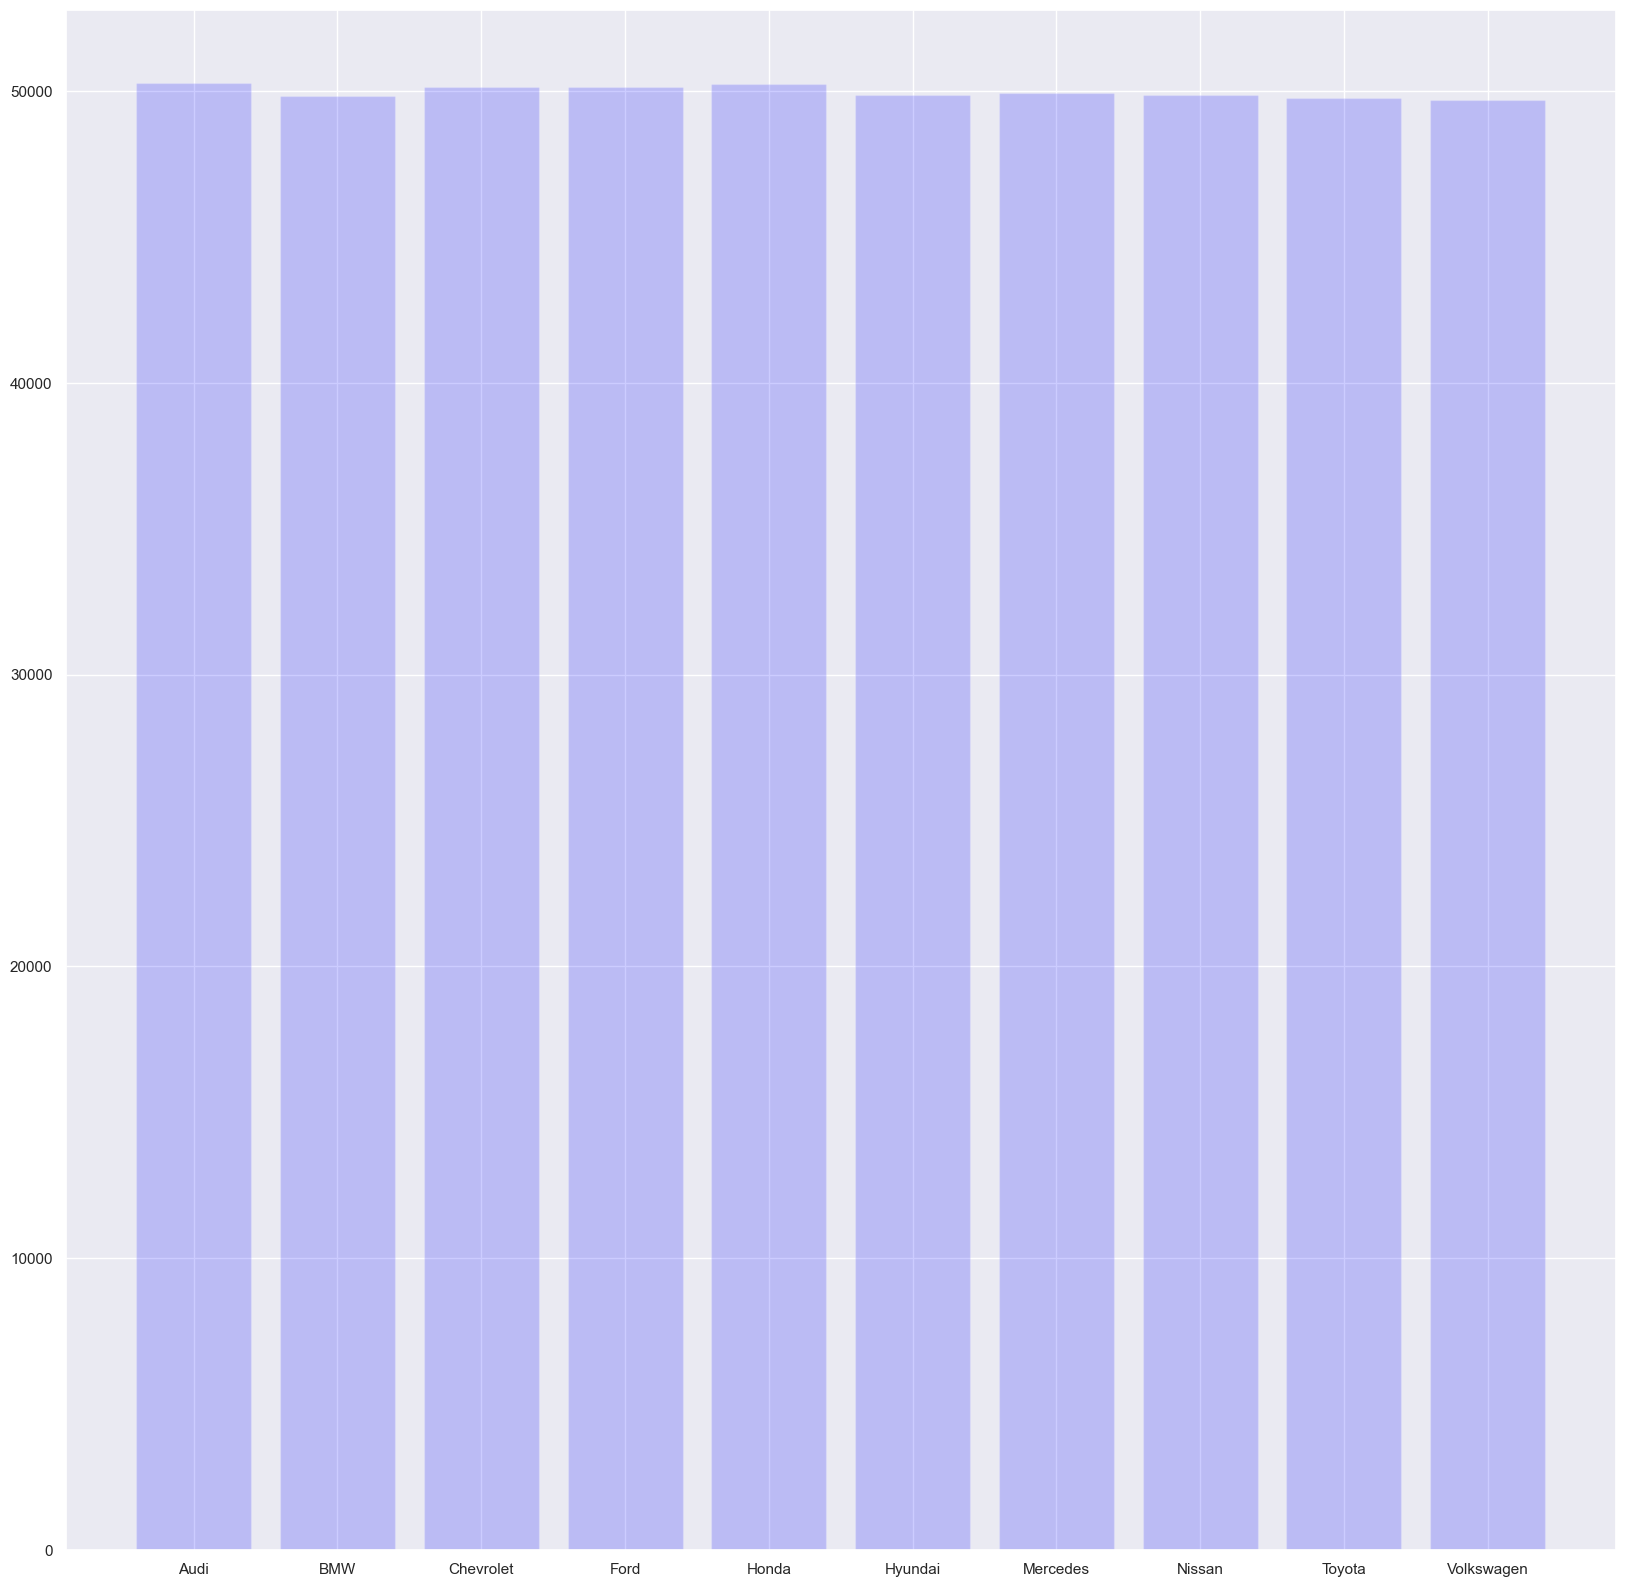

In [27]:
data= inner_merged_df['manufacturer']
unique_values,counts = np.unique(data,return_counts=True)
plt.figure(figsize=(20,20))
plt.bar(unique_values,counts, alpha=0.2, color='blue', edgecolor='white')
plt.show()




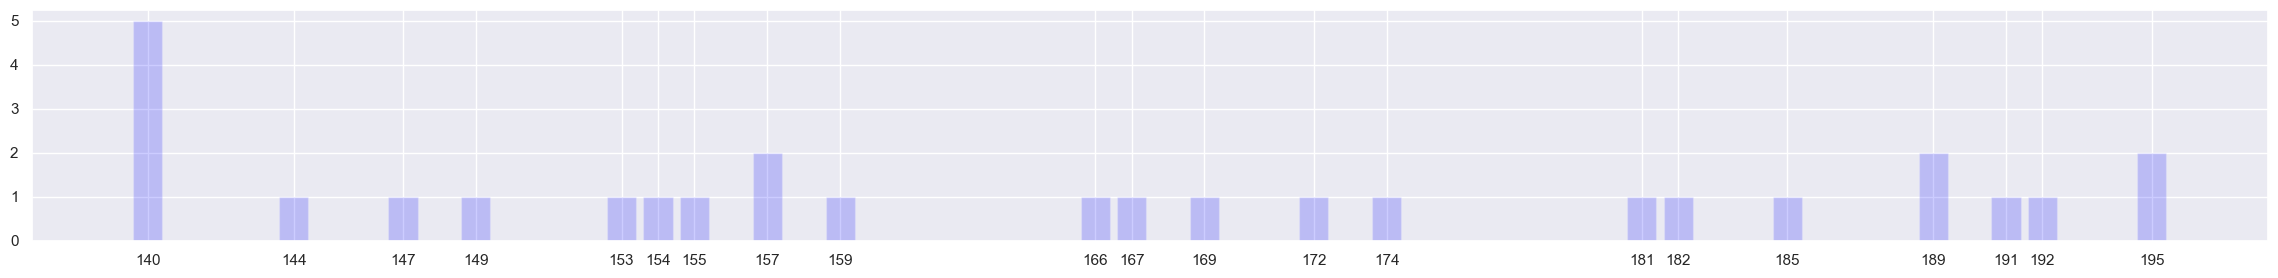

In [28]:
data = [140, 189, 185, 195, 149, 189, 147, 154, 174, 169, 195, 159, 192, 155, 191, 153, 157, 140, 144, 140, 172, 157, 181, 182, 166, 167, 140, 140]
unique_values, counts = np.unique(data, return_counts=True)
# Create a bar chart
plt.figure(figsize=(23, 3))
plt.bar(unique_values, counts, alpha=0.2, color='blue', edgecolor='white')
# Set x-ticks to show all unique values
plt.xticks(unique_values)
# Show the plot
plt.tight_layout() # Adjust layout to prevent clipping of labels
plt.show()

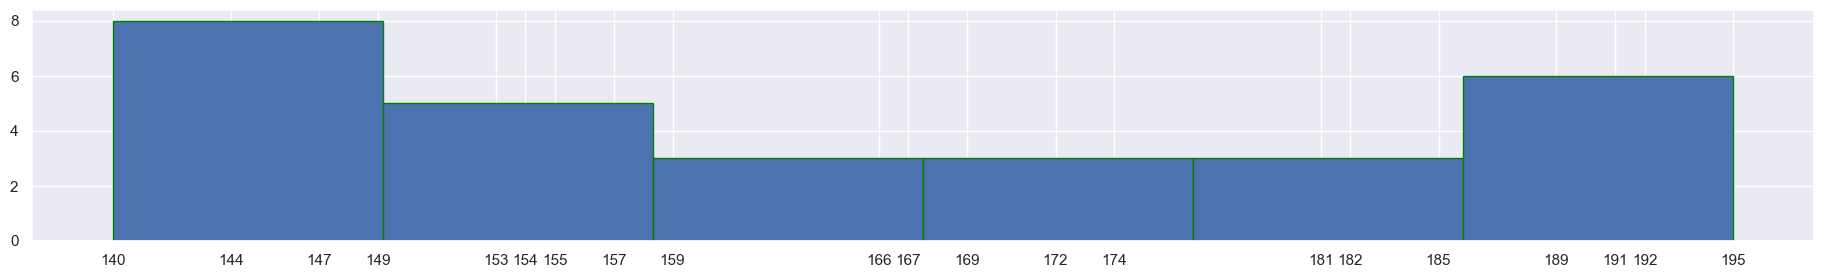

In [29]:
number_of_bins = int(np.ceil(np.log2(len(data))+1))#sturgey's rule

plt.figure(figsize=(23,3))
plt.hist(data,bins=number_of_bins,edgecolor='green')
plt.xticks(unique_values)
plt.show()

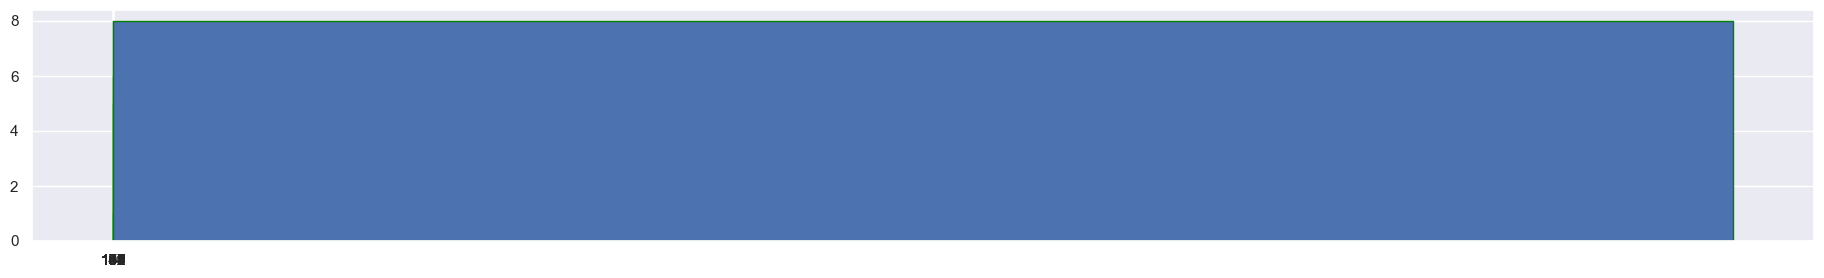

In [30]:
plt.figure(figsize=(23,3))
plt.hist(data,bins=[140,150,160,175,182,190200],edgecolor='green')
plt.xticks(unique_values)
plt.show()

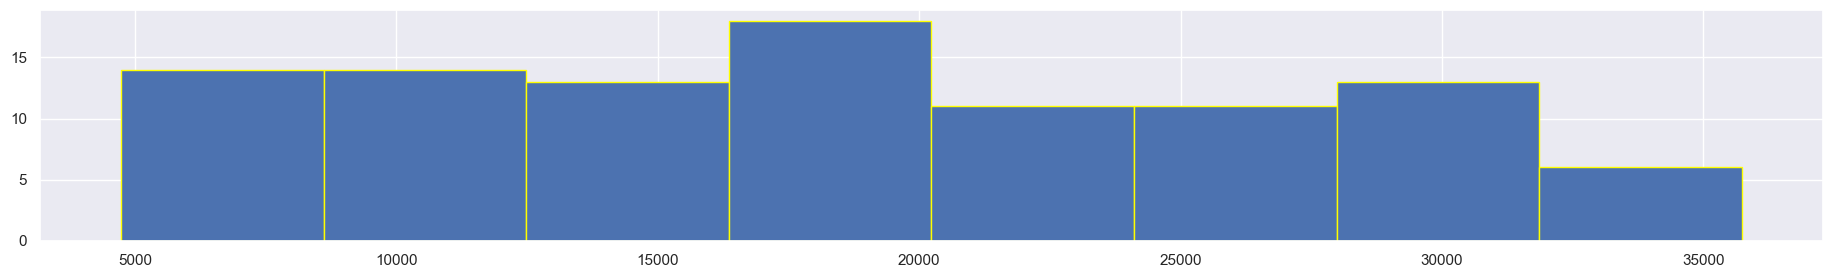

In [31]:
proposed_purchase_price = inner_merged_df['proposed_purchase_price']
data = proposed_purchase_price.head(100)
# unique_values, counts = np.unique(data, return_counts=True)
number_of_bins = int(np.ceil(np.log2(len(data))+1))
plt.figure(figsize=(23,3))
ax=plt.hist(data,bins=number_of_bins,edgecolor="yellow")
# plt.xticks(unique_values)
plt.show()

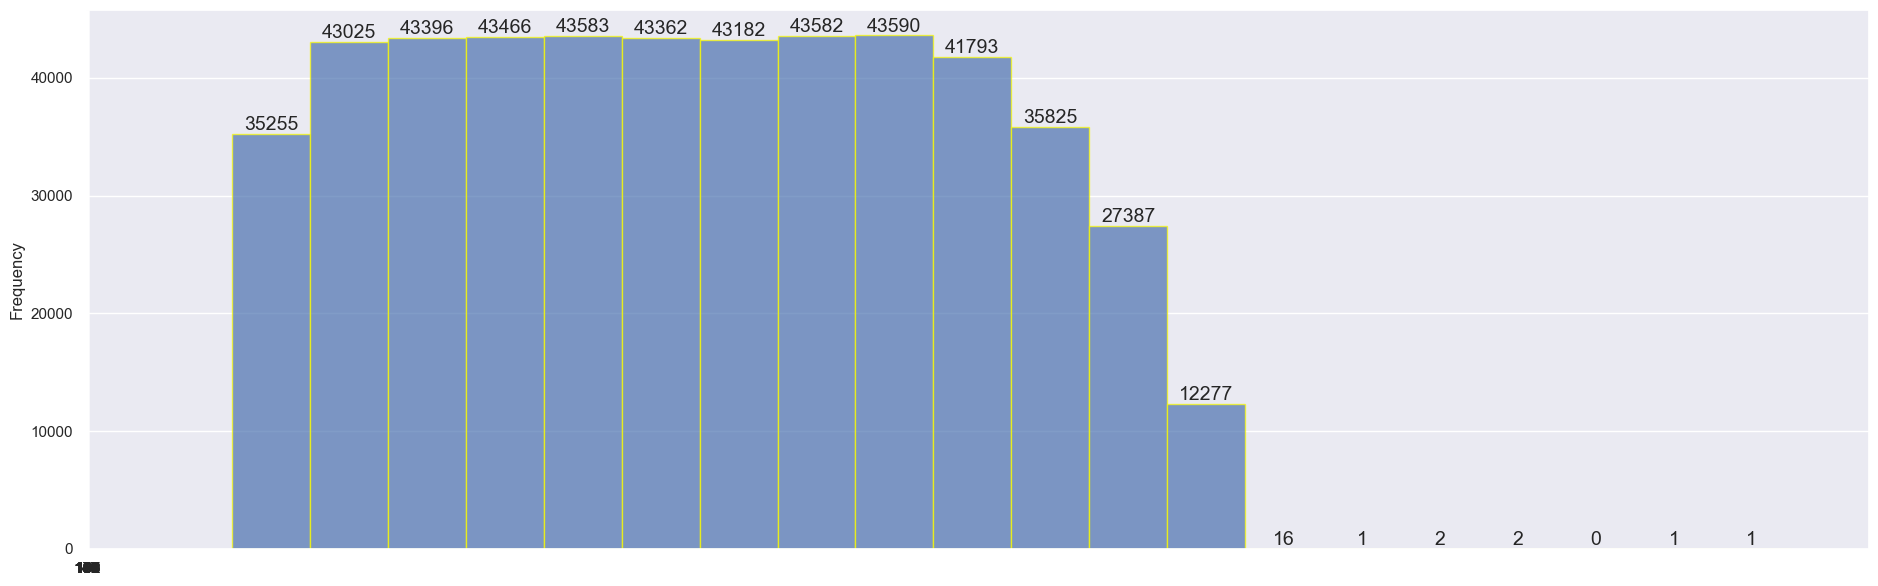

In [32]:
import numpy as np
# Calculate the sample size (n)
n=inner_merged_df["proposed_purchase_price"].count()
#Calculate the number of bins using the sturges's rule
k=int(np.ceil(np.log2(n)+1))
plt.figure(figsize=(23,7))
#Create a histogram of the proprosed purchase_price
ax = inner_merged_df["proposed_purchase_price"].plot.hist(bins=k, alpha=0.7, edgecolor="yellow")
# Annotate frequency values on the top
for p in ax.patches:
    height = p.get_height()
    # Get the x-coordinates for the graph
    x=p.get_x() + p.get_width()/2
    #place the text above the bar
    plt.text(x,height,str(int(height)),ha='center', va='bottom')
plt.xticks(unique_values)
plt.show()



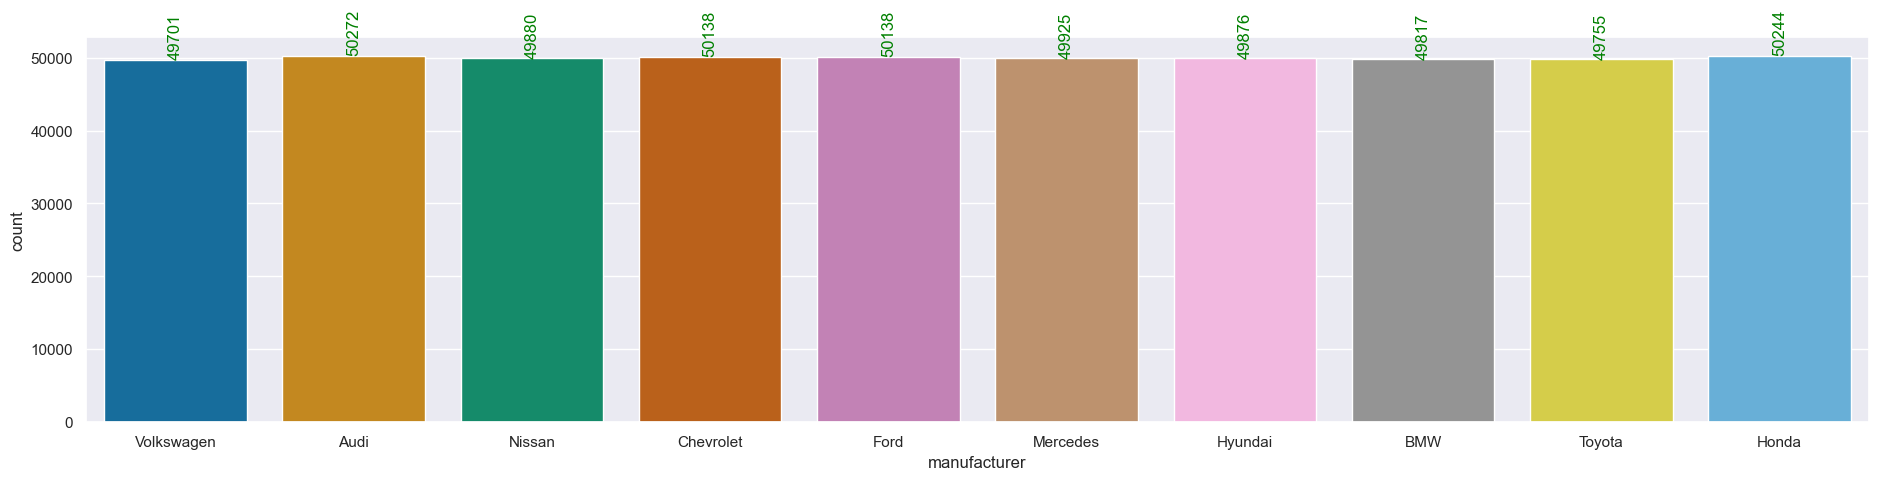

In [33]:
plt.figure(figsize=(23,5))
ax=sns.countplot(x='manufacturer',data=inner_merged_df,hue='manufacturer',palette='colorblind',legend=False)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=12, color='green',rotation=90)
plt.show() 

In [34]:
print('helloworld')

helloworld


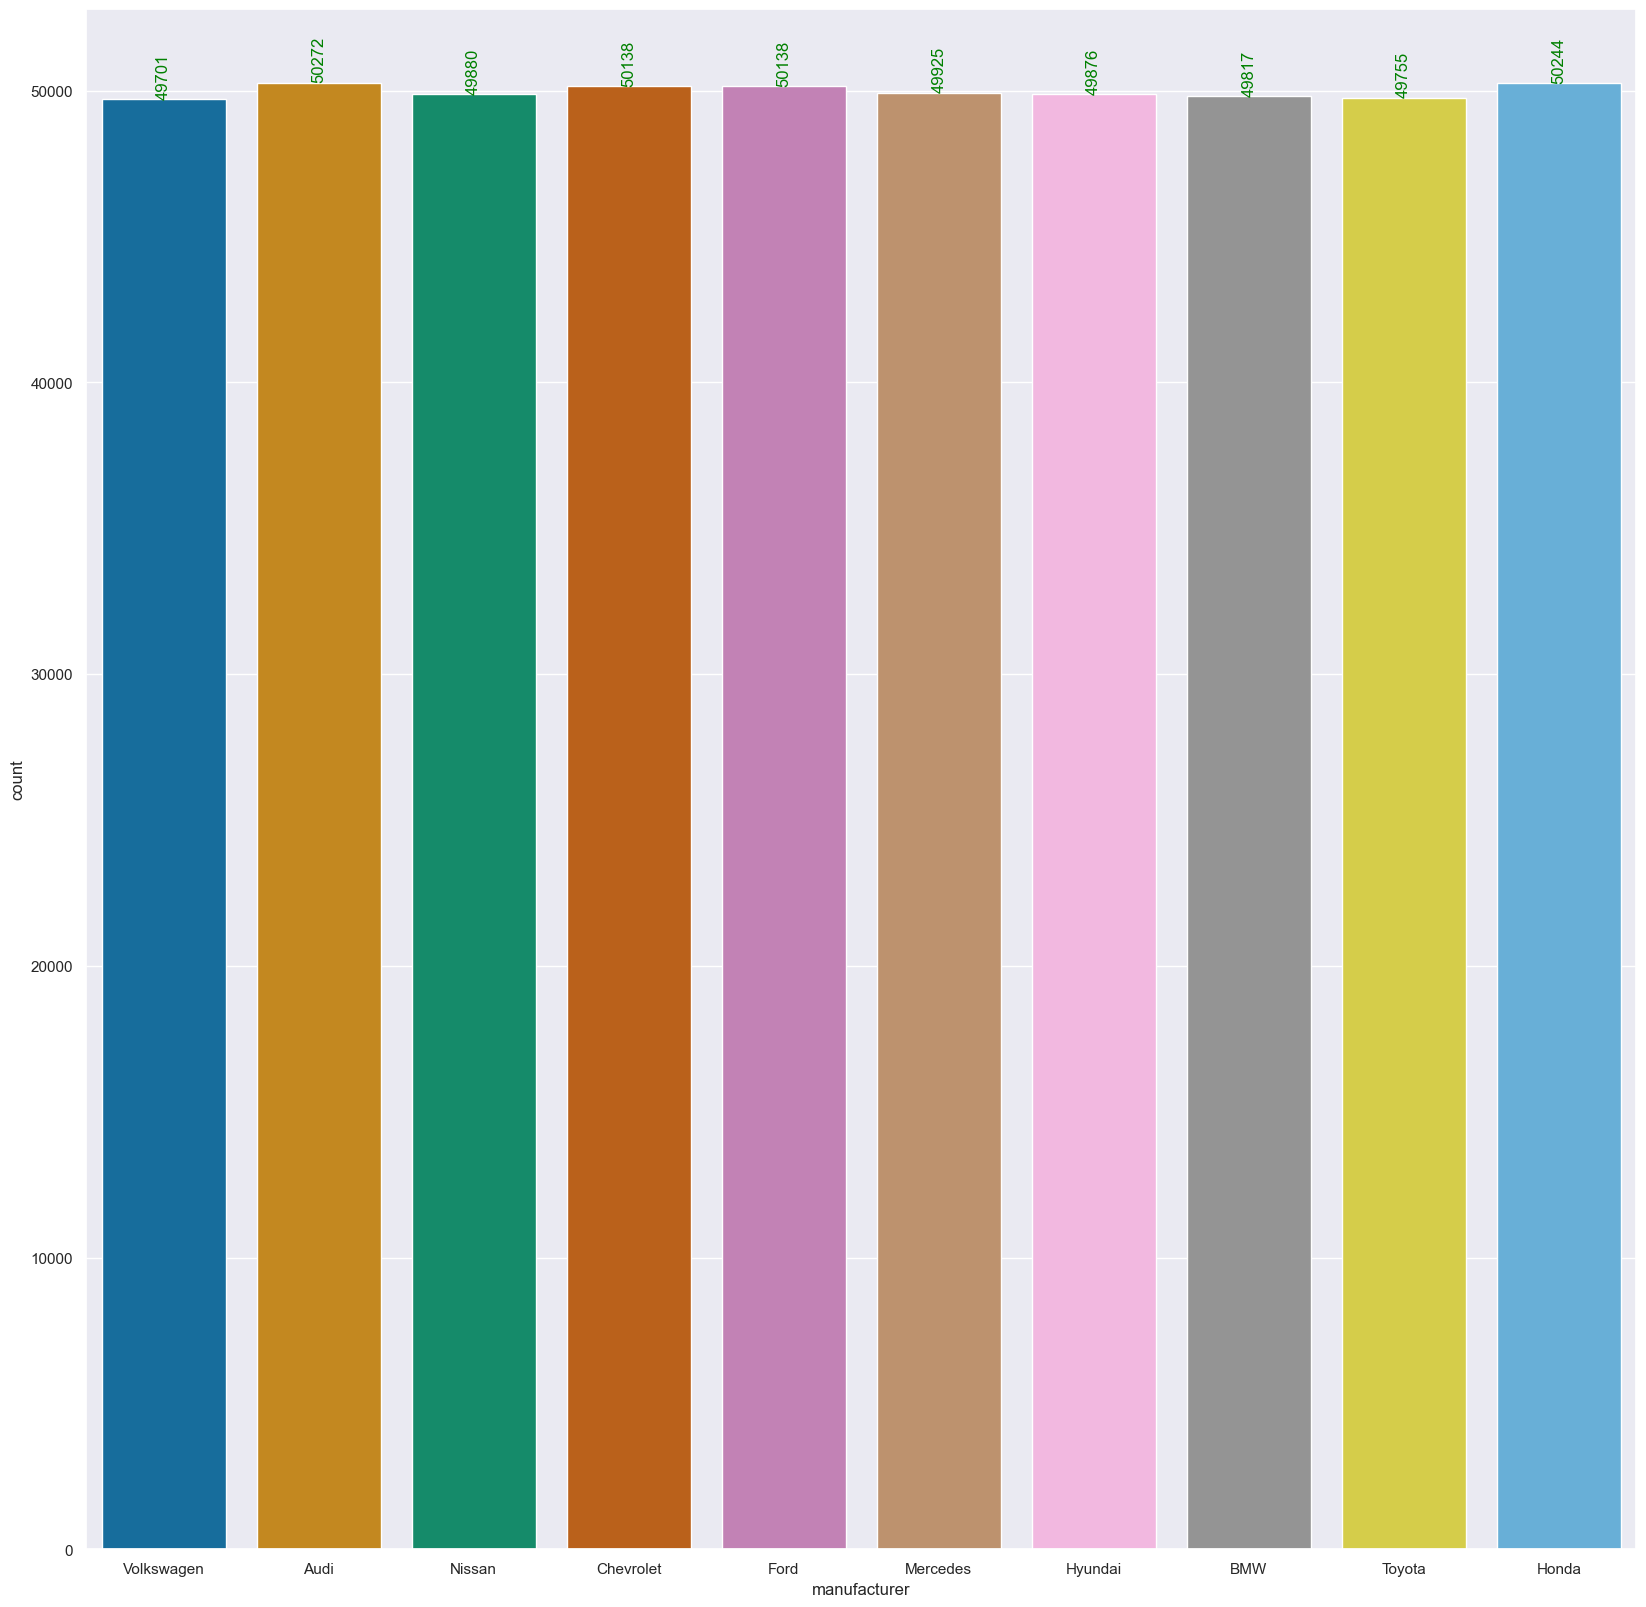

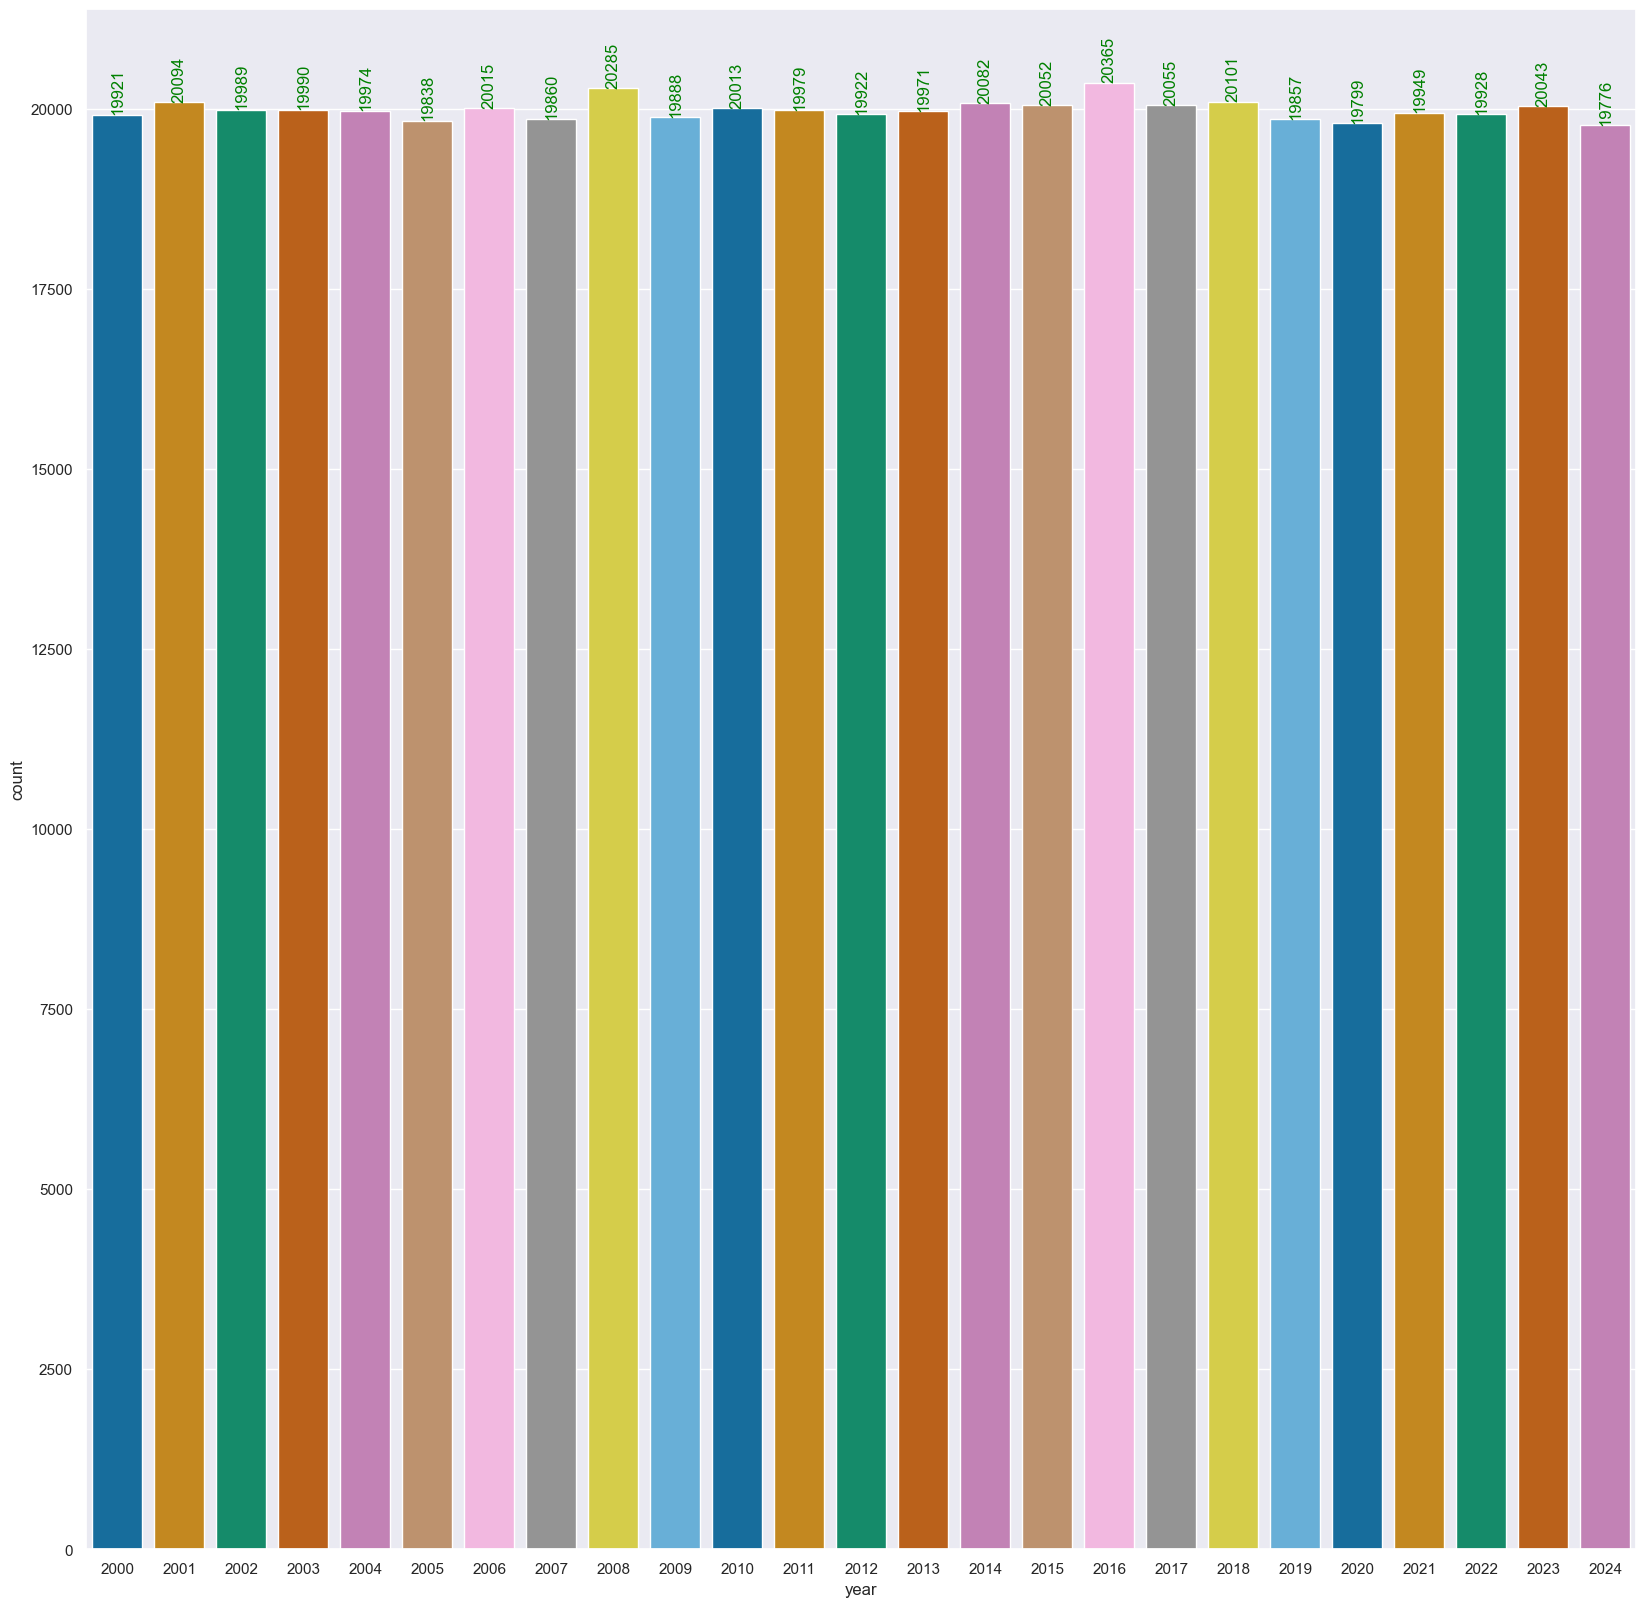

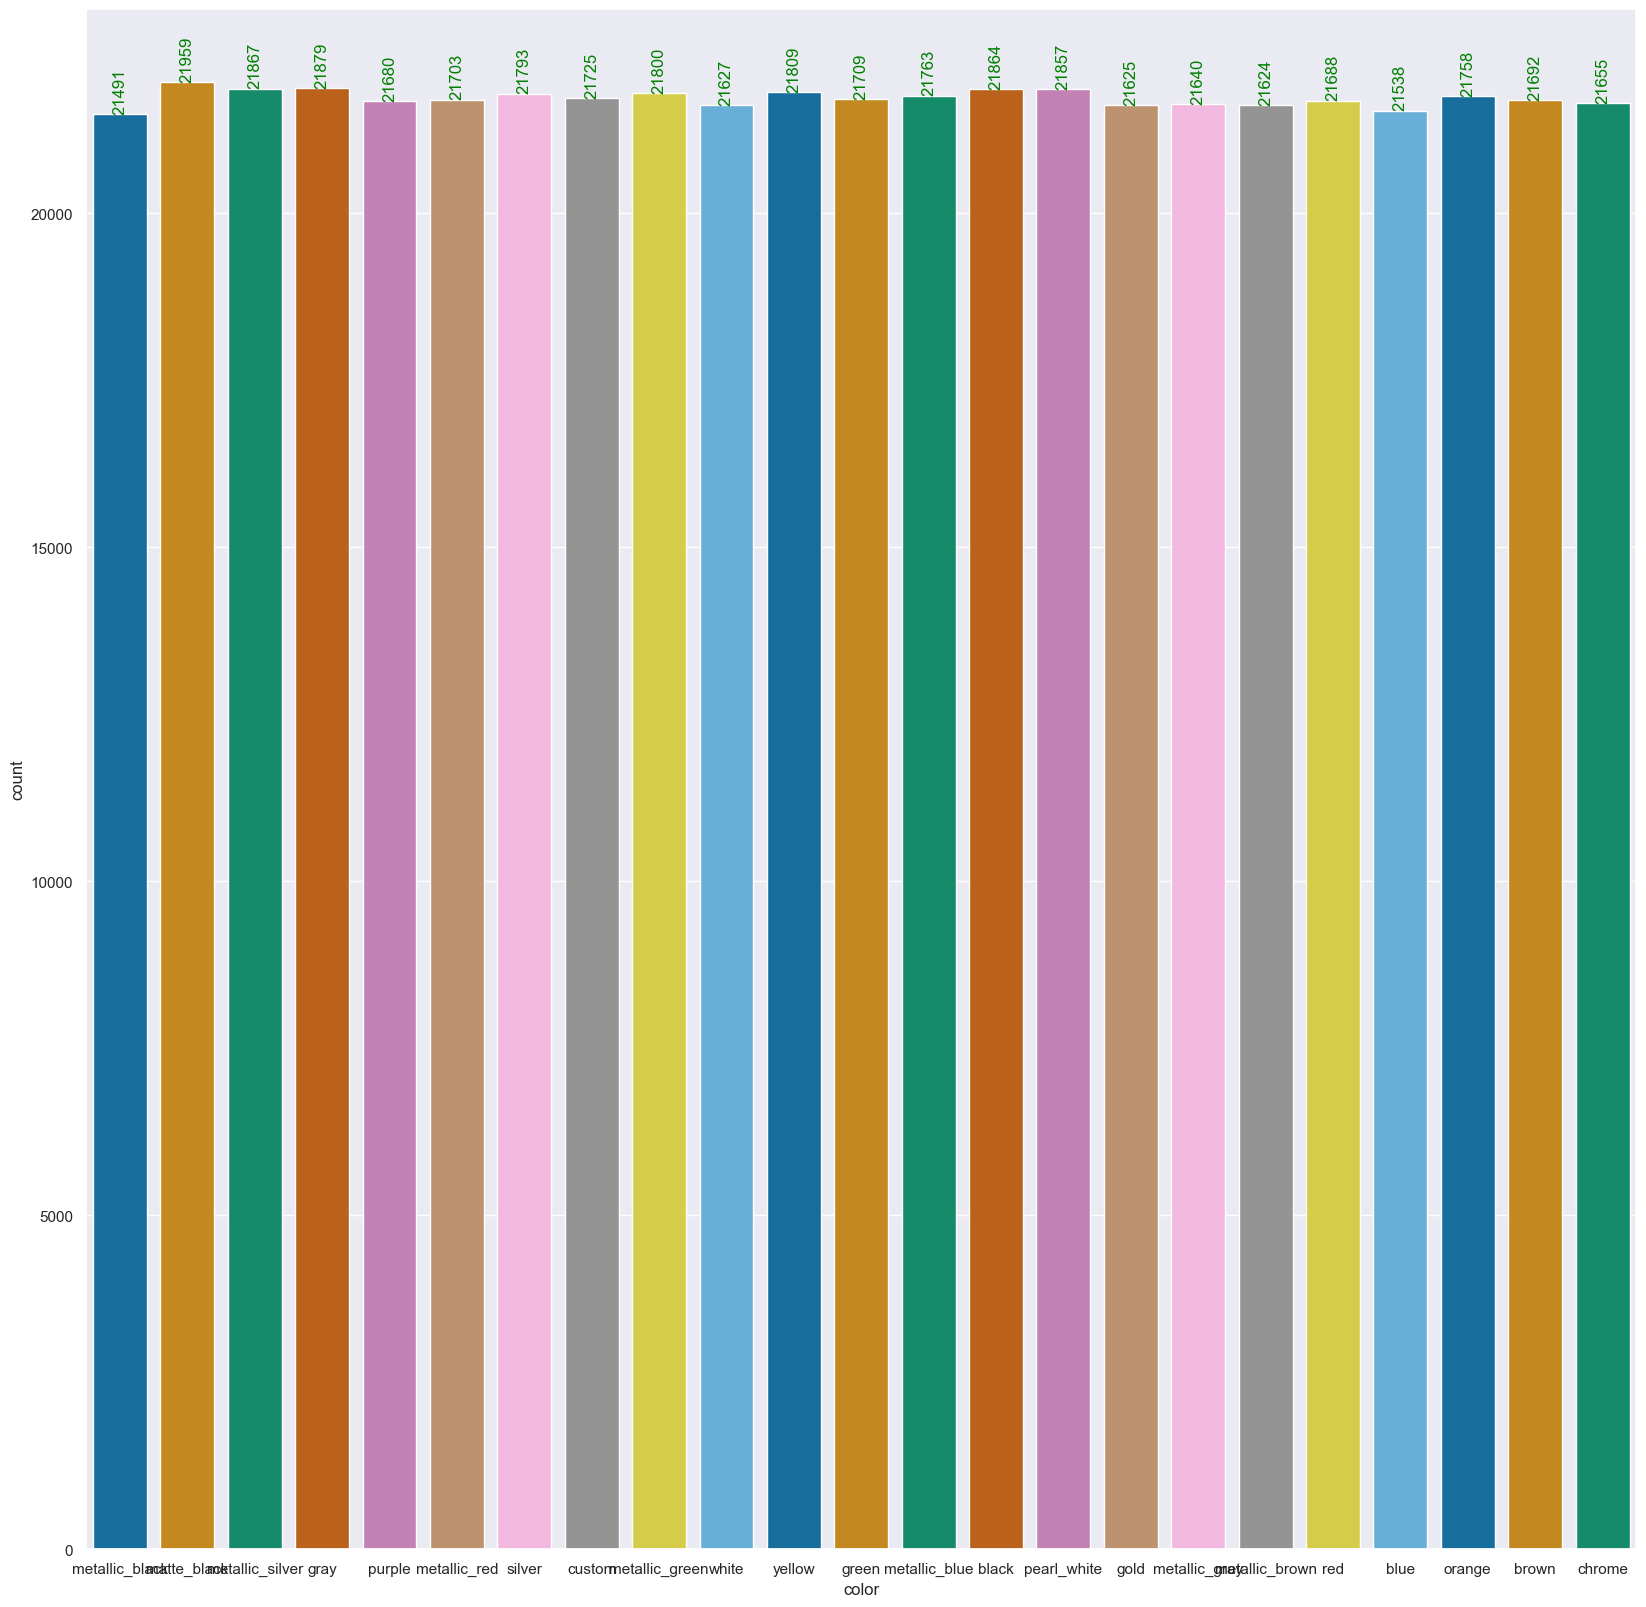

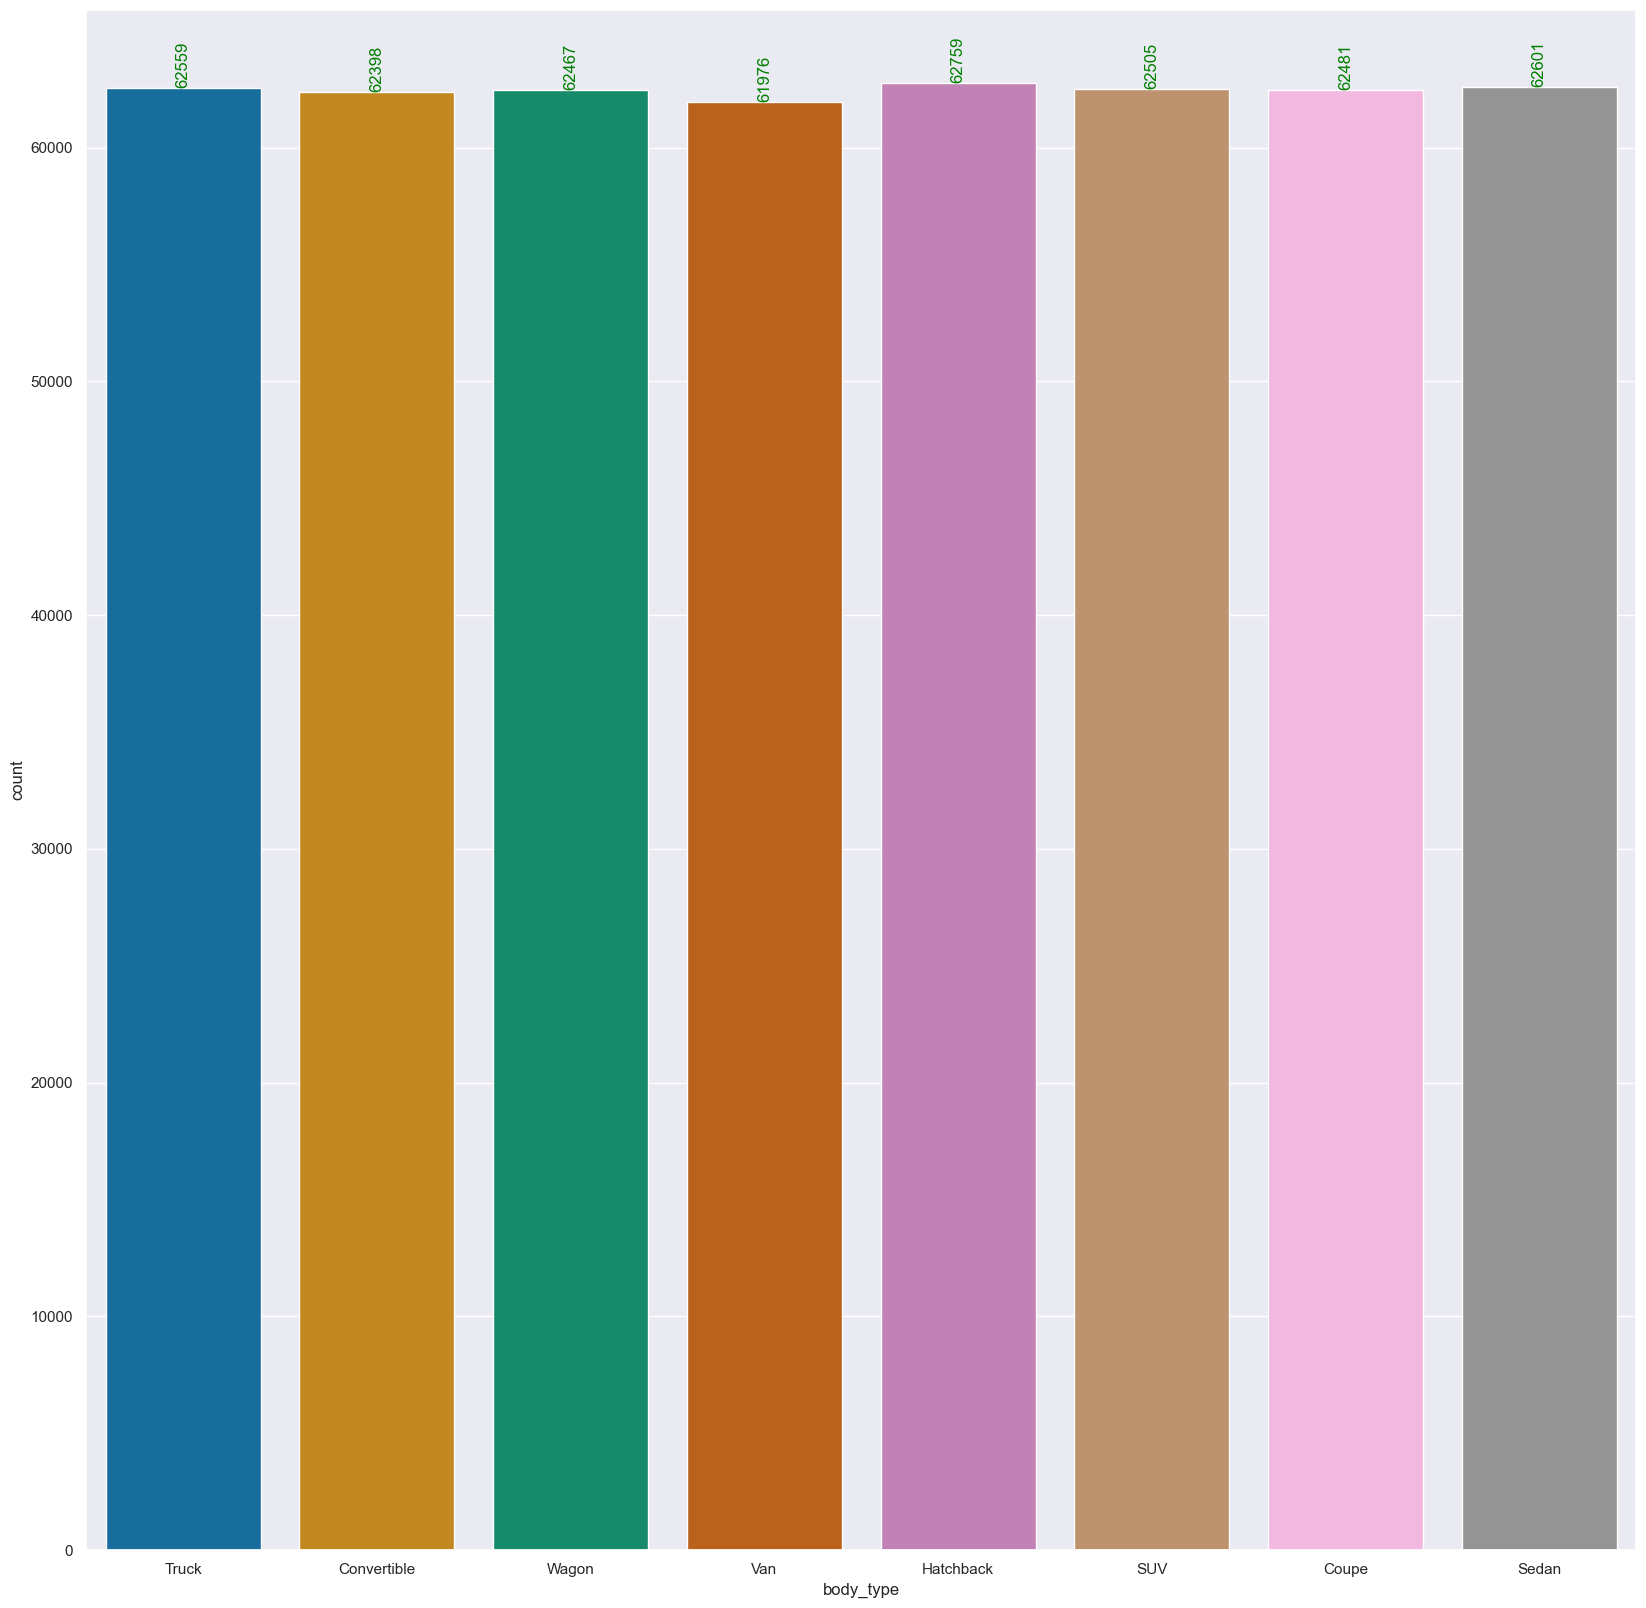

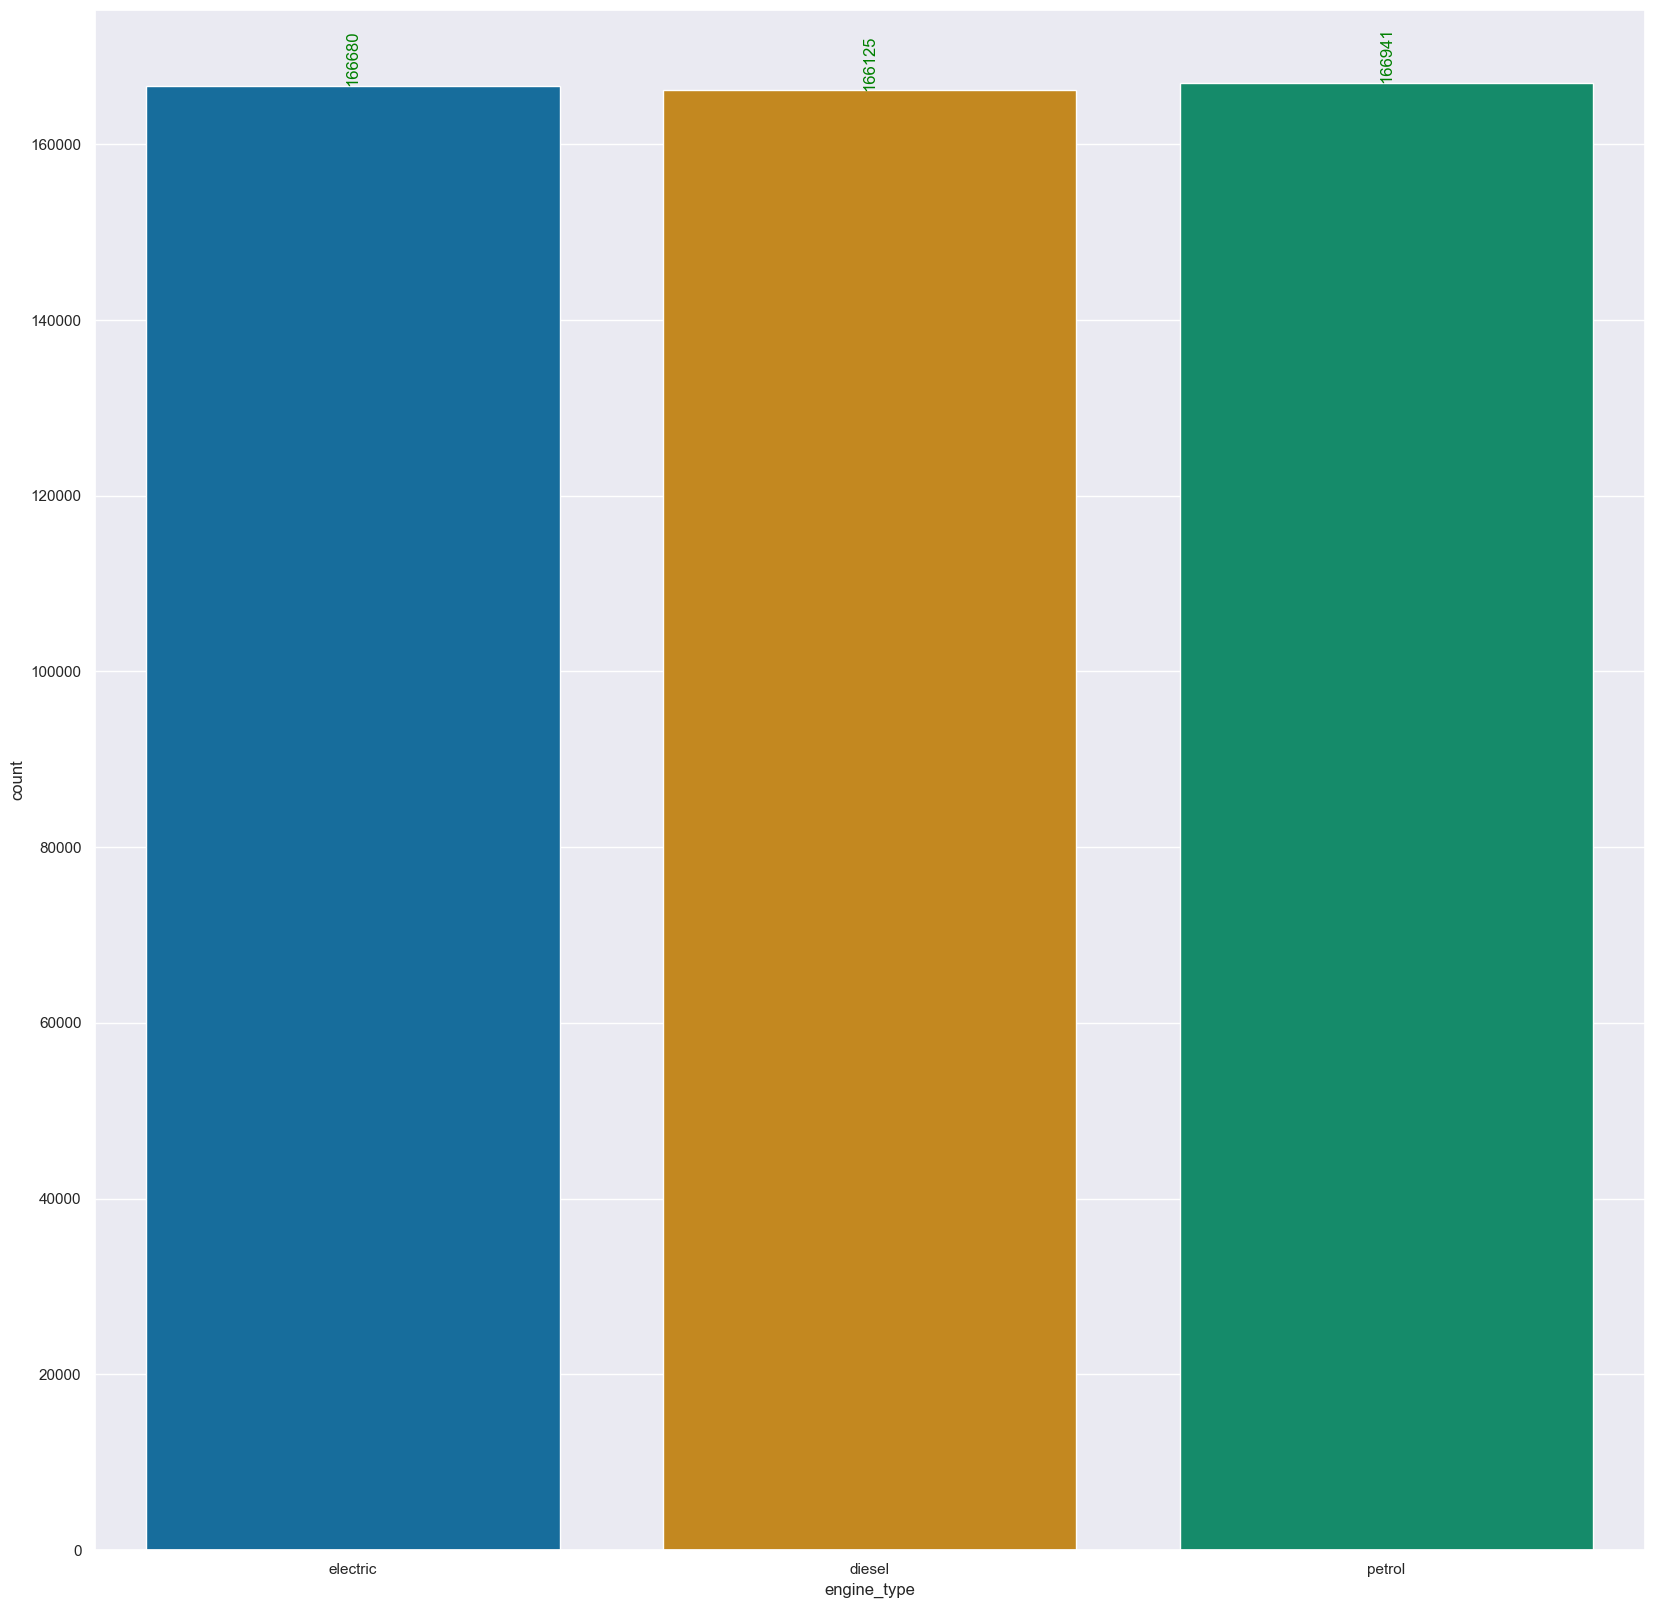

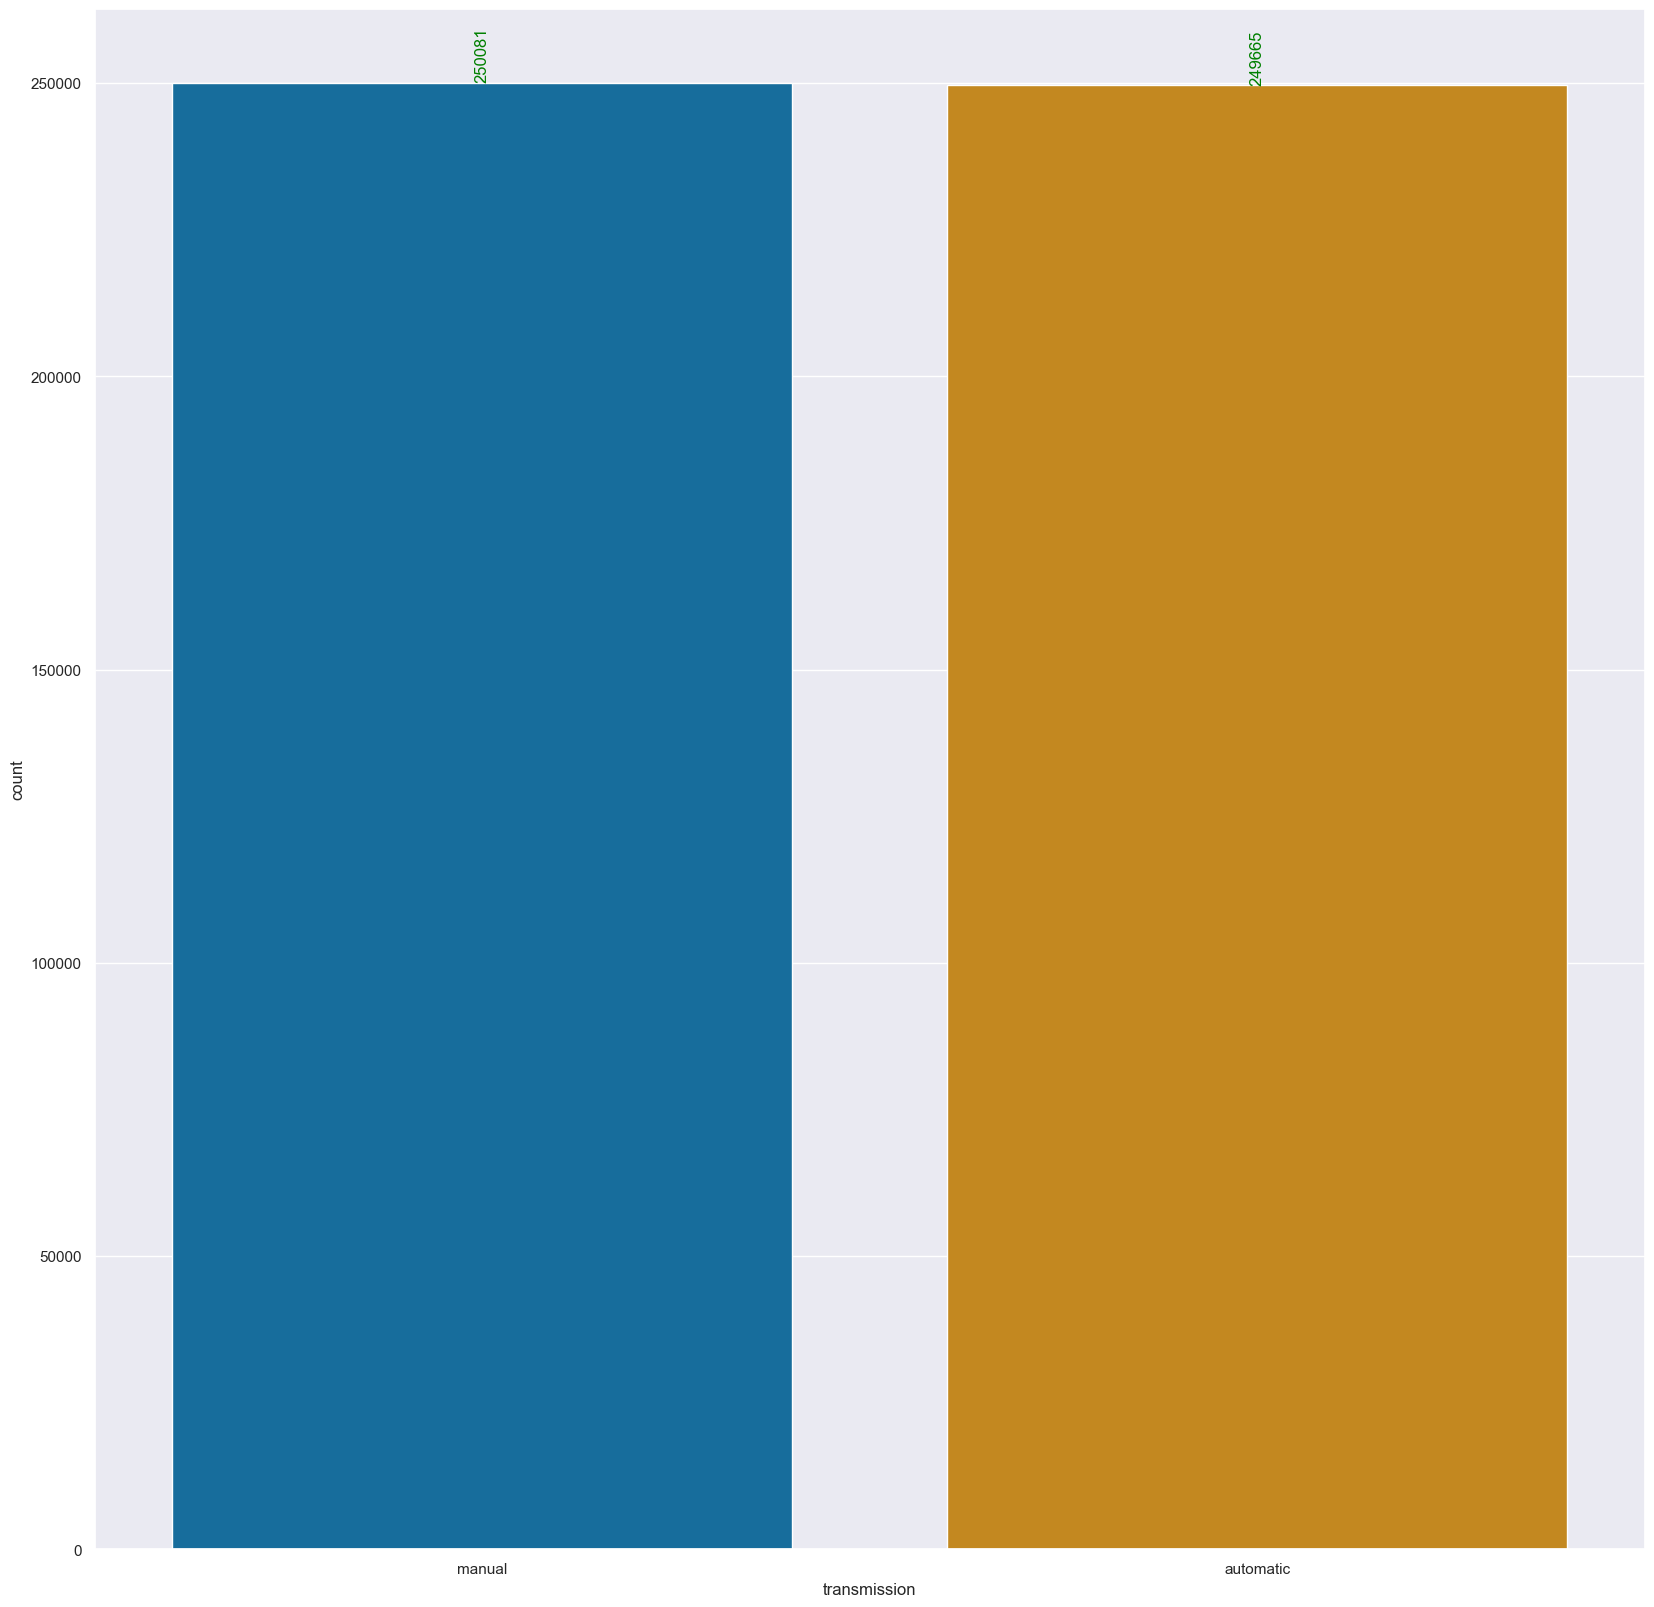

In [35]:
for col in ['manufacturer','year','color','body_type','engine_type','transmission']:
    ax=sns.countplot(x=col,data=inner_merged_df,hue=col,palette='colorblind',legend=False)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=12, color='green',rotation=90)
    plt.show()

In [37]:
ct=inner_merged_df[inner_merged_df['selling_price']>20000]
pd.crosstab(ct.selling_price, ct.seating_capacity)

seating_capacity,2,3,4,5,6,7,8,9,10
selling_price,,,,,,,,,
20376.02,0,0,1,0,0,0,0,0,0
20376.17,0,0,1,0,0,0,0,0,0
20376.26,0,0,0,0,0,0,0,1,0
20376.36,0,0,0,0,1,0,0,0,0
20376.37,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...
31899.86,0,0,0,0,0,0,0,0,1
31899.89,0,0,0,0,0,0,0,0,1
31899.92,0,0,0,0,0,0,1,0,0


In [39]:
ct=inner_merged_df[inner_merged_df['selling_price']>2020]
pd.crosstab(ct.year, ct.owner_district)

owner_district,east_bugesera,east_gatsibo,east_kayonza,east_kirehe,east_ngoma,east_nyagatare,east_rwamagana,kigali_gasabo,kigali_kicukiro,kigali_nyarugenge,...,south_nyanza,south_nyaruguru,south_ruhango,west_karongi,west_ngororero,west_nyabihu,west_nyamasheke,west_rubavu,west_rusizi,west_rutsiro
year,,,,,,,,,,,,,,,,,,,,,
2000,680,639,636,662,639,642,654,687,669,665,...,703,643,625,675,637,666,697,700,665,648
2001,639,672,666,627,688,673,644,747,687,662,...,702,665,634,650,685,679,731,626,687,620
2002,676,669,645,655,706,647,669,650,615,660,...,689,696,685,709,648,606,615,672,632,660
2003,644,677,675,672,720,636,649,712,649,668,...,671,651,695,656,665,688,667,666,677,657
2004,652,642,636,667,686,645,654,674,664,707,...,682,647,661,700,650,698,605,629,687,691
2005,664,650,661,639,673,677,651,670,671,711,...,668,690,644,674,624,656,682,661,626,598
2006,664,622,667,668,671,670,690,685,639,659,...,646,674,694,707,608,693,706,697,672,646
2007,573,578,584,541,571,604,573,556,549,556,...,529,593,554,577,523,551,544,560,537,563
2008,564,572,571,562,585,544,560,579,572,561,...,594,581,557,577,585,540,581,559,545,644


In [40]:
ct=inner_merged_df[inner_merged_df['selling_price']>2020]
pd.crosstab(ct.owner_age, ct.manufacturer)

manufacturer,Audi,BMW,Chevrolet,Ford,Honda,Hyundai,Mercedes,Nissan,Toyota,Volkswagen
owner_age,,,,,,,,,,
18,602,565,624,645,606,618,654,589,609,599
19,575,609,627,603,605,617,599,562,583,591
20,574,614,571,623,589,552,577,615,587,610
21,597,624,594,611,621,593,577,621,575,555
22,594,574,624,618,581,611,578,590,601,561
...,...,...,...,...,...,...,...,...,...,...
96,574,591,611,576,596,599,571,598,562,643
97,658,574,616,596,605,603,565,577,621,615
98,536,629,593,588,605,589,628,576,636,594


In [41]:
ct=inner_merged_df[inner_merged_df['selling_price']>2020]
pd.crosstab(ct.seating_capacity, ct.manufacturer)

manufacturer,Audi,BMW,Chevrolet,Ford,Honda,Hyundai,Mercedes,Nissan,Toyota,Volkswagen
seating_capacity,,,,,,,,,,
2,5593,5529,5637,5392,5708,5642,5645,5513,5554,5450
3,5497,5425,5479,5611,5665,5467,5530,5581,5565,5565
4,5588,5514,5623,5666,5492,5615,5533,5617,5613,5466
5,5633,5480,5478,5508,5572,5613,5618,5674,5433,5655
6,5519,5415,5530,5583,5602,5585,5498,5438,5508,5493
7,5558,5520,5649,5694,5595,5409,5487,5502,5601,5428
8,5465,5820,5546,5517,5574,5470,5565,5569,5480,5522
9,5723,5514,5495,5615,5473,5418,5568,5559,5482,5621
10,5696,5600,5701,5552,5563,5657,5481,5427,5519,5501


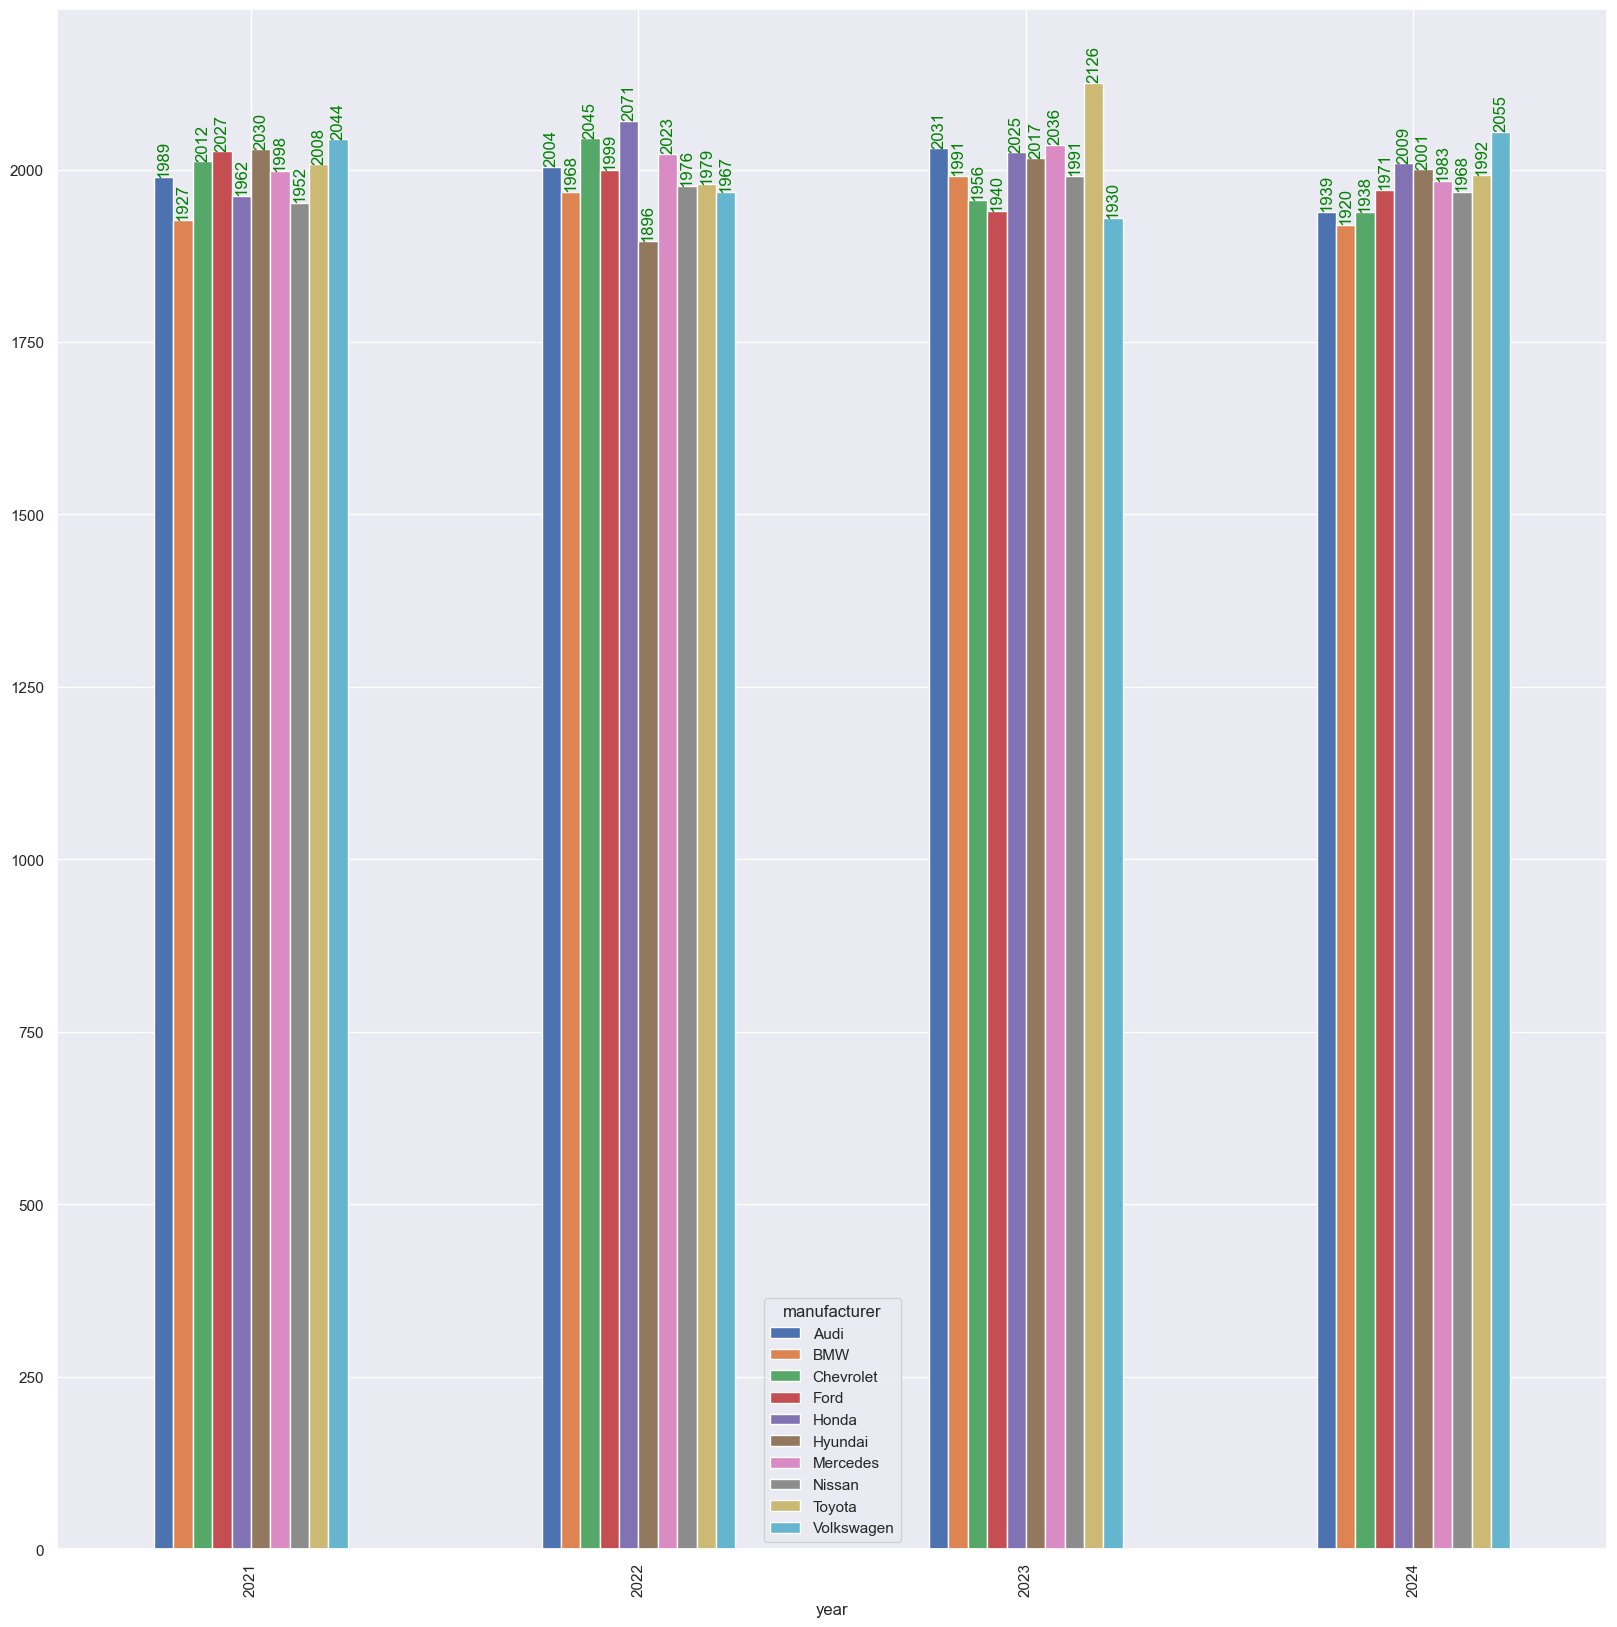

In [61]:
ct=inner_merged_df[inner_merged_df["year"]>2020]
ax = pd.crosstab(ct.year, ct.manufacturer).plot(kind= "bar")

for p in ax.patches:
   ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=12, color='green',rotation=90)
plt.show()

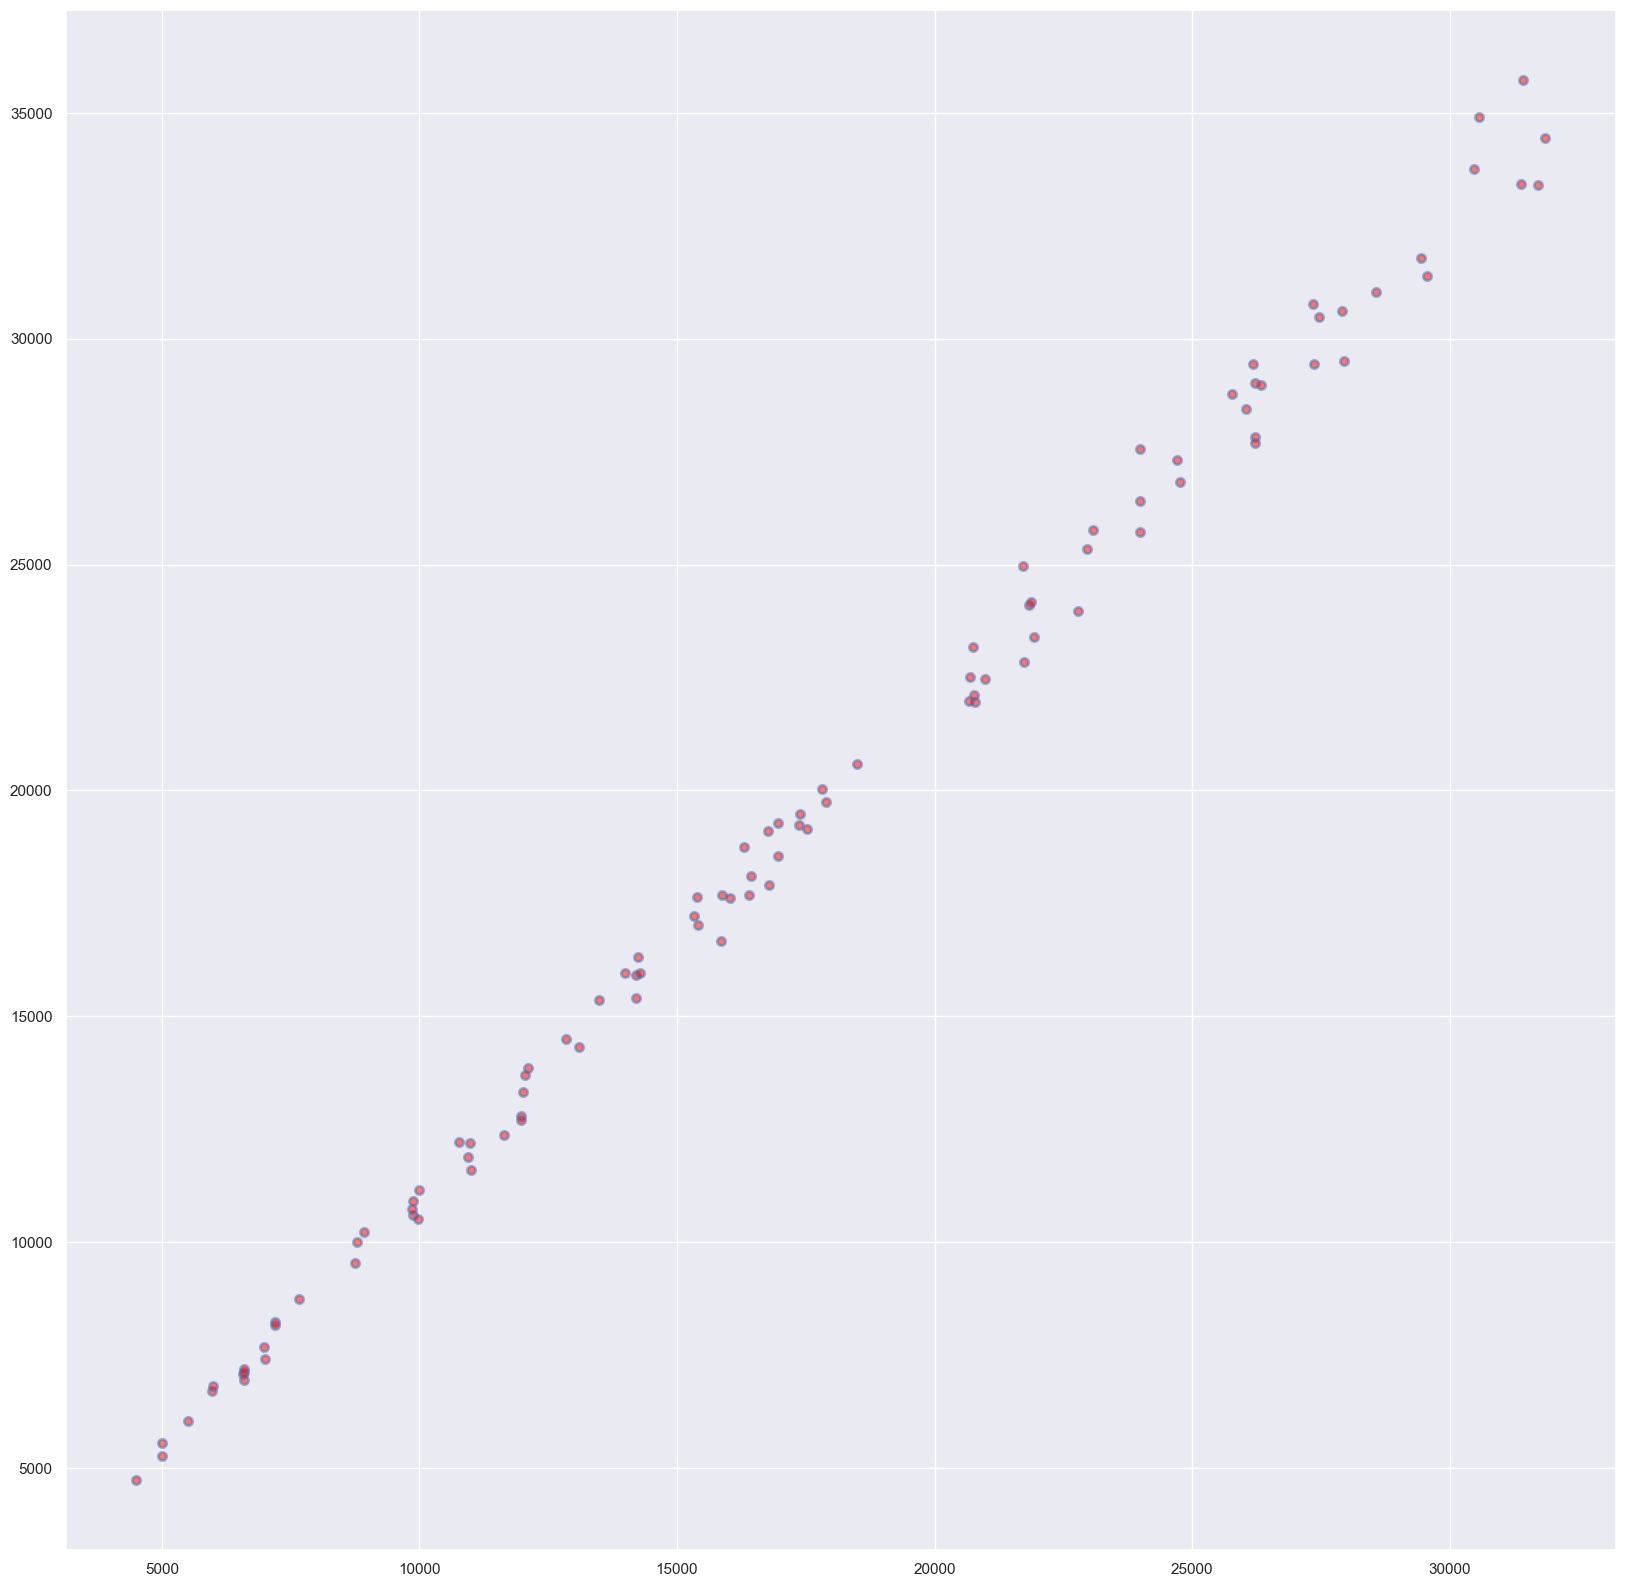

In [66]:
x = inner_merged_df['selling_price'][:100]
y = inner_merged_df['proposed_purchase_price'][:100]
plt.scatter(x,y, color='red', alpha=0.5, edgecolor='b', linewidth=2)
plt.show()


In [68]:
inner_merged_df.groupby('manufacturer')['selling_price'].sum()


manufacturer
Audi          8.889681e+08
BMW           8.828390e+08
Chevrolet     8.892914e+08
Ford          8.832898e+08
Honda         8.850742e+08
Hyundai       8.791838e+08
Mercedes      8.822122e+08
Nissan        8.791842e+08
Toyota        8.779599e+08
Volkswagen    8.767928e+08
Name: selling_price, dtype: float64

In [69]:
inner_merged_df.groupby('manufacturer')['selling_price',].count()

manufacturer
Audi          50272
BMW           49817
Chevrolet     50138
Ford          50138
Honda         50244
Hyundai       49876
Mercedes      49925
Nissan        49880
Toyota        49755
Volkswagen    49701
Name: selling_price, dtype: int64

In [71]:
inner_merged_df.groupby('manufacturer')[['selling_price','proposed_purchase_price']].count() #this is beacuse we are passing there a list of values 

,selling_price,proposed_purchase_price
manufacturer,,
Audi,50272,50272
BMW,49817,49817
Chevrolet,50138,50138
Ford,50138,50138
Honda,50244,50244
Hyundai,49876,49876
Mercedes,49925,49925
Nissan,49880,49880
Toyota,49755,49755


In [74]:
inner_merged_df.groupby(['manufacturer','fuel_type','transmission'])[['selling_price','proposed_purchase_price']].sum()

selling_price  proposed_purchase_price
manufacturer fuel_type transmission                                        
Audi         biodiesel automatic       64456047.57              70879042.85
                       manual          65063407.77              71527694.75
             diesel    automatic       62189927.69              68424975.77
                       manual          62311002.39              68542839.61
             electric  automatic       64040434.32              70478067.15
...                                            ...                      ...
Volkswagen   gasoline  manual          61595373.93              67750480.85
             hybrid    automatic       63290939.70              69630972.24
                       manual          62883156.59              69150082.43
             hydrogen  automatic       62391601.84              68603713.60
                       manual          61745281.74              67900677.50

[140 rows x 2 columns]

In [77]:
inner_merged_df.groupby(['manufacturer','fuel_type','engine_type','transmission'])[['selling_price','proposed_purchase_price']].count()

selling_price  \
manufacturer fuel_type engine_type transmission                  
Audi         biodiesel diesel      automatic              1160   
                                   manual                 1242   
                       electric    automatic              1277   
                                   manual                 1231   
                       petrol      automatic              1201   
...                                                        ...   
Volkswagen   hydrogen  diesel      manual                 1133   
                       electric    automatic              1217   
                                   manual                 1117   
                       petrol      automatic              1120   
                                   manual                 1227   

                                                 proposed_purchase_price  
manufacturer fuel_type engine_type transmission                           
Audi         biodiesel diesel      automatic                        1160  
                                   manual                           1242  
                       electric    automatic                        1277  
                                   manual                           1231  
                       petrol      automatic                        1201  
...                                                                  ...  
Volkswagen   hydrogen  diesel      manual                           1133  
                       electric    automatic                        1217  
                                   manual                           1117  
                       petrol      automatic                        1120  
                                   manual                           1227  

[420 rows x 2 columns]

In [86]:
#aggregating with groupby 
inner_merged_df.groupby(['manufacturer','fuel_type']).agg({
    'seating_capacity':['min','max','mean','std','first','last'],
    
    'owner_district':['count','unique'],
    'year':['min','max','mean','std','sum']
})    

seating_capacity                                     \
                                    min max      mean       std first last   
manufacturer fuel_type                                                       
Audi         biodiesel                2  10  6.030683  2.583734     7   10   
             diesel                   2  10  5.960991  2.594637     4    3   
             electric                 2  10  5.999316  2.606017     5    8   
             ethanol                  2  10  6.021018  2.595082     5    4   
             gasoline                 2  10  6.022992  2.588995     3   10   
...                                 ...  ..       ...       ...   ...  ...   
Volkswagen   electric                 2  10  6.017795  2.587015     3    5   
             ethanol                  2  10  6.016860  2.559153    10    6   
             gasoline                 2  10  5.999712  2.557221     6   10   
             hybrid                   2  10  6.048188  2.587311     9    4   
             hydrogen                 2  10  5.945259  2.587737     5   10   

                       owner_district  \
                                count   
manufacturer fuel_type                  
Audi         biodiesel           7333   
             diesel              7101   
             electric            7309   
             ethanol             7232   
             gasoline            7220   
...                               ...   
Volkswagen   electric            7137   
             ethanol             7236   
             gasoline            6946   
             hybrid              7118   
             hydrogen            6960   

                                                                           \
                                                                   unique   
manufacturer fuel_type                                                      
Audi         biodiesel  [west_nyamasheke, kigali_kicukiro, east_rwamag...   
             diesel     [west_rubavu, west_nyamasheke, south_gisagara,...   
             electric   [west_karongi, kigali_gasabo, south_gisagara, ...   
             ethanol    [north_burera, east_gatsibo, east_bugesera, we...   
             gasoline   [south_muhoza, north_musanze, south_huye, sout...   
...                                                                   ...   
Volkswagen   electric   [east_nyagatare, south_huye, kigali_kicukiro, ...   
             ethanol    [east_nyagatare, east_bugesera, kigali_kicukir...   
             gasoline   [east_nyagatare, north_rulindo, west_rutsiro, ...   
             hybrid     [west_nyabihu, east_ngoma, kigali_gasabo, west...   
             hydrogen   [east_rwamagana, west_rutsiro, south_nyamagabe...   

                        year                                         
                         min   max         mean       std       sum  
manufacturer fuel_type                                               
Audi         biodiesel  2000  2024  2011.993727  7.147019  14753950  
             diesel     2000  2024  2012.093930  7.162740  14287879  
             electric   2000  2024  2011.853605  7.130665  14704638  
             ethanol    2000  2024  2011.887721  7.277980  14549972  
             gasoline   2000  2024  2011.989612  7.217479  14526565  
...                      ...   ...          ...       ...       ...  
Volkswagen   electric   2000  2024  2012.179908  7.225575  14360928  
             ethanol    2000  2024  2012.079464  7.218625  14559407  
             gasoline   2000  2024  2012.100489  7.170392  13976050  
             hybrid     2000  2024  2011.955325  7.172651  14321098  
             hydrogen   2000  2024  2011.819828  7.263284  14002266  

[70 rows x 13 columns]

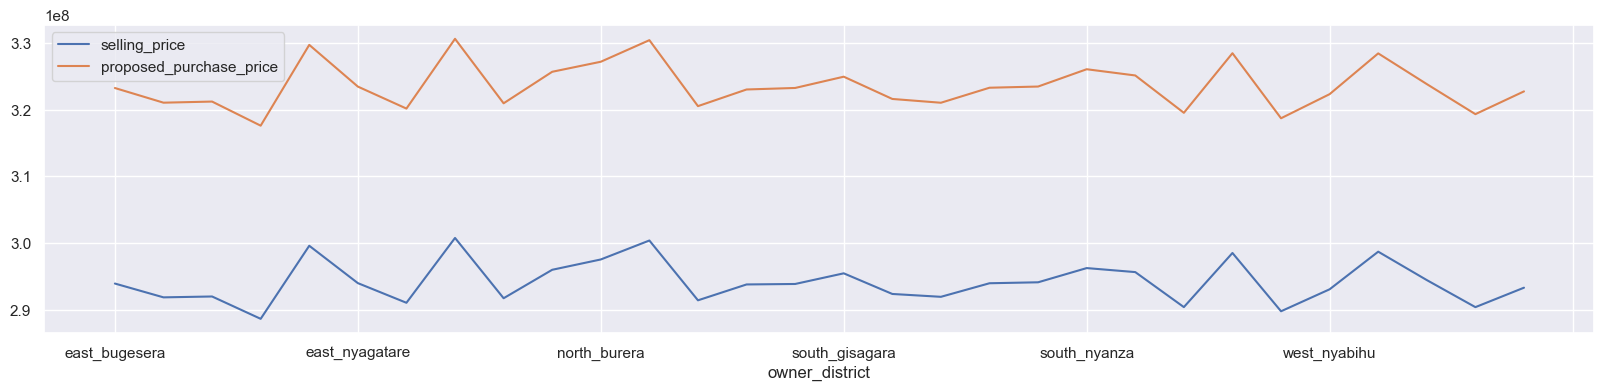

In [102]:

gd=inner_merged_df.groupby('owner_district')[['selling_price','proposed_purchase_price']].sum()
gd.plot(figsize=(20,4))
plt.show()

In [ ]:
gd=inner_merged_df.groupby('owner_district')[['selling_price','proposed_purchase_price']].sum()
gd.plot(kind='barh',figsize=(20,8))
plt.show()

In [ ]:
gd=inner_merged_df.groupby('owner_district')[['selling_price','proposed_purchase_price']].sum()
gd.plot(kind='bar',figsize=(20,4))
plt.show()

In [ ]:
mydataset = inner_merged_df.groupby('owner_district')[['selling_price','proposed_purchase_price']]
# mydataset['profit'] = mydataset['proposed_purchase_price']-mydataset['selling_price']
mydataset.head()
mydataset.plot(kind='barh',figsize=(20,4))
plt.show()

In [ ]:
ax= inner_merged_df.groupby('manufacturer')[['selling_price','proposed_purchase_price']].sum().plot(kind='bar')
for bars in ax.containers:
    ax.bar_label(bars,fmt='%.2f')
plt.show()

In [ ]:
# correlation matrix n .corr
inner_merged_df[['owner_age', 'selling_price', 'proposed_purchase_price', 'year', 'kilometers_driven']].corr()


In [ ]:
plt.figure(figsize = (20, 3))
numeric_columns = ['owner_age', 'selling_price', 'proposed_purchase_price', 'year', 'kilometers_driven']
heatmap_data = inner_merged_df[numeric_columns].corr()
sns.heatmap(heatmap_data,
            cmap = 'BuPu',
            annot = True,
            linewidths=0.5,
            fmt= ".2f");
plt.show()